# DSP Mini-Project — Combined Notebook (Members 1–4)

One notebook for the whole project, in member order:

1. **Member 1** — CWRU dataset, kinematics, preprocessing, baseline spectra; MFPT dataset analysis.
2. **Member 2** — Kurtogram-guided band selection, Kaiser FIR vs Butterworth SOS, Figures 1–2.
3. **Member 3** — Hilbert squared envelope, calibrated SES, CA-CFAR / Median–MAD thresholding, Figure 3.
4. **Member 4** — Batch benchmark over CWRU faults, defect sizes and loads plus the MFPT load sweep, fixed-point analysis, Figure 4.

Members 2–4 consume the recordings loaded by Member 1: CWRU Drive-End records (inner, ball and outer race; 7, 14 and 21 mil; 0–3 HP) and, in Member 4's MFPT table, the inner/outer race load sweeps (0–300 lb). The CWRU archive is cloned from GitHub on first run; the MFPT recordings ship as `datasets/MPFT.zip` and are extracted automatically.


# Member 1 — Vidyashankar T

# DSP Mini-Project Member 1 - Vidyashankar T : CWRU Bearing Signal Analysis

**Scope:** CWRU data loading, bearing kinematic frequencies, signal preprocessing, baseline FFT/STFT, spectral window comparison, and multi load comparison for inner race, ball, and outer race faults.

**Dataset:** [CWRU Bearing NumPy repository](https://github.com/srigas/CWRU_Bearing_NumPy). The code analyses 12 comparable DE12 records: 7 mil defects, drive end channel, 12 kHz sampling, four motor speeds (1797, 1772, 1750, and 1730 RPM). The outer race defect is selected at the 6 o'clock position.

## 1. Environment and imports

In [1]:
from pathlib import Path
import re
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

OUTPUT_DIR = Path("outputs/CWRU_Member1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Output directory:", OUTPUT_DIR.resolve())

Working directory: /home/darshan/DLA/run_nb
Output directory: /home/darshan/DLA/run_nb/outputs/CWRU_Member1


## 2. Download and locate the CWRU dataset

In [2]:
REPOSITORY_URL = "https://github.com/srigas/CWRU_Bearing_NumPy.git"
DATA_ROOT = Path("datasets/CWRU_Bearing_NumPy")

if not DATA_ROOT.exists():
    DATA_ROOT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["git", "clone", REPOSITORY_URL, str(DATA_ROOT)],
        check=True
    )
else:
    print("CWRU repository already exists; skipping download.")

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"CWRU dataset folder not found: {DATA_ROOT}")

npz_files = sorted(DATA_ROOT.rglob("*.npz"))
print("CWRU .npz files found:", len(npz_files))
if not npz_files:
    raise FileNotFoundError("No .npz files found. Check the repository download.")

CWRU repository already exists; skipping download.
CWRU .npz files found: 161


## 3. Bearing geometry and theoretical fault frequencies

For the CWRU SKF 6205 drive-end bearing, the geometry used here is:

- Number of rolling elements: 9
- Rolling-element diameter: 7.94 mm
- Pitch diameter: 39.04 mm
- Contact angle: 0°

The characteristic frequencies are calculated from shaft speed. They are **theoretical reference frequencies**, not measured spectral peaks.

In [3]:
# CWRU SKF 6205 drive-end bearing geometry
N_ROLLING = 9
BALL_DIAMETER_MM = 7.94
PITCH_DIAMETER_MM = 39.04
CONTACT_ANGLE_DEG = 0.0


def kinematic_fault_frequencies(rpm):
    """Return ideal BPFO, BPFI, BSF and FTF in Hz for the CWRU 6205 bearing."""
    rpm = float(rpm)
    if not np.isfinite(rpm) or rpm <= 0:
        raise ValueError("RPM must be a positive finite value.")

    shaft_rate_hz = rpm / 60.0
    ratio = (BALL_DIAMETER_MM / PITCH_DIAMETER_MM) * np.cos(
        np.deg2rad(CONTACT_ANGLE_DEG)
    )

    return {
        "BPFO_Hz": (N_ROLLING / 2) * shaft_rate_hz * (1 - ratio),
        "BPFI_Hz": (N_ROLLING / 2) * shaft_rate_hz * (1 + ratio),
        "BSF_Hz": (PITCH_DIAMETER_MM / (2 * BALL_DIAMETER_MM)) * shaft_rate_hz * (1 - ratio**2),
        "FTF_Hz": (shaft_rate_hz / 2) * (1 - ratio),
        "shaft_rate_Hz": shaft_rate_hz,
        "shaft_rpm": rpm,
    }


LOAD_TO_RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}
frequency_rows = []
for load_hp, rpm in LOAD_TO_RPM.items():
    frequency_rows.append({"Load_HP": load_hp, "RPM": rpm, **kinematic_fault_frequencies(rpm)})

cwru_frequency_table = pd.DataFrame(frequency_rows)
display(cwru_frequency_table.round(3))

,Load_HP,RPM,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz,shaft_rate_Hz,shaft_rpm
0,0,1797,107.364,162.186,70.585,11.929,29.950,1797.0
1,1,1772,105.871,159.929,69.603,11.763,29.533,1772.0
2,2,1750,104.556,157.944,68.738,11.617,29.167,1750.0
3,3,1730,103.361,156.139,67.953,11.485,28.833,1730.0


At 1797 RPM, the calculated BPFO and BPFI are approximately 107.36 Hz and 162.19 Hz. As shaft speed decreases with increasing motor load in these recordings, the corresponding theoretical fault frequencies decrease proportionally.

## 4. Discrete-time fault signal model

A localized bearing defect can be represented as a sequence of impacts exciting the bearing housing resonance:

\[
x(t)=\sum_m A_m h(t-t_m)+w(t), \qquad t_m\approx\frac{m}{f_{\mathrm{fault}}}+\epsilon_m,
\]

where \(A_m\) is impact amplitude, \(h(t)\) is the structural impulse response, \(w(t)\) is background vibration/noise, and \(\epsilon_m\) represents timing variation such as slip. A simple damped resonant response is

\[
h(t)=e^{-\sigma t}\cos(2\pi f_r t)u(t).
\]

After sampling at \(f_s\),

\[
x[n]=\sum_m A_m h[n-n_m]+w[n].
\]

The baseline FFT and STFT characterize the measured signal. They do not perform resonance demodulation or make a fault decision; those are later project stages.

## 5. Signal loading and DSP helper functions

In [4]:
SAMPLING_RATE_HZ = 12_000.0
WINDOWS = ("boxcar", "hann", "blackman")
WINDOW_LABELS = {
    "boxcar": "Rectangular",
    "hann": "Hann",
    "blackman": "Blackman",
}


def load_cwru_de12(path):
    """Load the Drive-End channel from a CWRU DE12 .npz record."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    with np.load(path, allow_pickle=False) as archive:
        if "DE" not in archive.files:
            raise KeyError(f"DE channel not found in {path.name}; keys: {archive.files}")
        x = np.asarray(archive["DE"], dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16 or not np.all(np.isfinite(x)):
        raise ValueError(f"Invalid signal array in {path.name}: shape={x.shape}")
    return x


def preprocess_signal(x):
    """Remove the DC mean and return signal plus amplitude statistics."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16 or not np.all(np.isfinite(x)):
        raise ValueError("Expected a finite one-dimensional signal of at least 16 samples.")
    dc_offset = float(np.mean(x))
    demeaned = x - dc_offset
    rms = float(np.sqrt(np.mean(demeaned**2)))
    peak = float(np.max(np.abs(demeaned)))
    normalized = demeaned / rms if rms > np.finfo(float).eps else demeaned.copy()
    stats = {"dc_offset": dc_offset, "rms": rms, "peak": peak}
    return demeaned, normalized, stats


def single_sided_amplitude_spectrum(x, fs, window="hann", nfft=None):
    """Coherent-gain-corrected one-sided amplitude spectrum."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16:
        raise ValueError("Expected a one-dimensional signal with at least 16 samples.")
    if window not in WINDOWS:
        raise ValueError(f"Window must be one of {WINDOWS}.")
    if nfft is None:
        nfft = x.size
    if nfft < x.size:
        raise ValueError("nfft must be >= signal length.")

    x = x - np.mean(x)
    w = signal.get_window(window, x.size, fftbins=True)
    scale = np.sum(w)
    spectrum = np.abs(np.fft.rfft(x * w, n=int(nfft))) / scale
    if int(nfft) % 2 == 0:
        if spectrum.size > 2:
            spectrum[1:-1] *= 2
    elif spectrum.size > 1:
        spectrum[1:] *= 2
    frequencies = np.fft.rfftfreq(int(nfft), d=1 / float(fs))
    return frequencies, spectrum


def compute_stft(x, fs, window="hann", nperseg=1024, noverlap=512):
    """Return frequency, time and complex STFT arrays."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16:
        raise ValueError("Expected a one-dimensional signal with at least 16 samples.")
    nperseg = min(int(nperseg), x.size)
    noverlap = min(int(noverlap), nperseg - 1)
    return signal.stft(
        x - np.mean(x), fs=float(fs), window=window,
        nperseg=nperseg, noverlap=noverlap,
        boundary=None, padded=False, detrend=False,
        return_onesided=True
    )

## 6. CWRU dataset inventory

In [5]:
def parse_cwru_filename(path):
    name = Path(path).stem
    rpm_match = re.search(r"(?<!\d)(1797|1772|1750|1730)(?!\d)", name)
    rpm = int(rpm_match.group(1)) if rpm_match else None

    if "normal" in name.lower():
        fault = "Normal"
    elif "_IR_" in name:
        fault = "Inner race"
    elif "_B_" in name:
        fault = "Ball"
    elif "_OR@" in name:
        fault = "Outer race"
    else:
        fault = "Unknown"

    size_match = re.search(r"(?:IR|B|OR@\d+)_(\d+)(?:_|$)", name)
    pos_match = re.search(r"OR@(\d+)", name)
    rate_match = re.search(r"DE(12|48)(?:_|$)", name)

    return {
        "file": Path(path).name,
        "rpm": rpm,
        "fault": fault,
        "defect_diameter_mil": int(size_match.group(1)) if size_match else None,
        "outer_race_position": int(pos_match.group(1)) if pos_match else None,
        "DE_sampling_rate_hz": int(rate_match.group(1)) * 1000 if rate_match else None,
        "path": str(path),
    }


manifest = [parse_cwru_filename(p) for p in npz_files]
manifest = [row for row in manifest if row["rpm"] is not None]
cwru_inventory = pd.DataFrame(manifest)
print("CWRU records in manifest:", len(cwru_inventory))
display(pd.crosstab(cwru_inventory["fault"], cwru_inventory["rpm"]))

fault_7mil_inventory = cwru_inventory[
    cwru_inventory["defect_diameter_mil"] == 7
]
print("7-mil records by fault and RPM:")
display(pd.crosstab(fault_7mil_inventory["fault"], fault_7mil_inventory["rpm"]))

CWRU records in manifest: 161


rpm,1730,1750,1772,1797
fault,,,,
Ball,10,10,10,10
Inner race,10,10,10,10
Normal,1,1,1,1
Outer race,19,19,19,20


7-mil records by fault and RPM:


rpm,1730,1750,1772,1797
fault,,,,
Ball,3,3,3,3
Inner race,3,3,3,3
Outer race,9,9,9,9


## 7. Select comparable CWRU records

To make a controlled comparison, the selected records use the same:

- Defect size: 7 mil
- Sensor channel: Drive End (`DE`)
- Sampling rate: 12 kHz (`DE12`)
- Motor speeds: 1797, 1772, 1750 and 1730 RPM

The selected outer race defect is at the 6 o'clock position. This gives 12 records in total: four for each fault type.

In [6]:
RPM_VALUES = [1797, 1772, 1750, 1730]
FAULT_SPECS = {
    "Inner Race": "IR_7",
    "Ball": "B_7",
    "Outer Race (6 o'clock)": "OR@6_7",
}

selected_paths = {}
missing_files = []
for fault_name, code in FAULT_SPECS.items():
    selected_paths[fault_name] = {}
    for rpm in RPM_VALUES:
        filename = f"{rpm}_{code}_DE12.npz"
        matches = list(DATA_ROOT.rglob(filename))
        if len(matches) != 1:
            missing_files.append(filename)
        else:
            selected_paths[fault_name][rpm] = matches[0]

if missing_files:
    raise FileNotFoundError("Missing or ambiguous selected files: " + ", ".join(missing_files))

print("Selected records:", sum(len(v) for v in selected_paths.values()))
for fault_name, files_by_rpm in selected_paths.items():
    print(f"{fault_name}: {len(files_by_rpm)} records")

Selected records: 12
Inner Race: 4 records
Ball: 4 records
Outer Race (6 o'clock): 4 records


## 8. Load the 12 selected vibration records

In [7]:
records_by_fault = {}
metadata_rows = []

for fault_name, files_by_rpm in selected_paths.items():
    records_by_fault[fault_name] = {}
    for rpm, path in files_by_rpm.items():
        x = load_cwru_de12(path)
        record = {
            "signal": x,
            "sampling_rate_hz": SAMPLING_RATE_HZ,
            "rpm": rpm,
            "load_hp": {1797: 0, 1772: 1, 1750: 2, 1730: 3}[rpm],
            "fault": fault_name,
            "path": str(path),
        }
        records_by_fault[fault_name][rpm] = record
        metadata_rows.append({
            "Fault": fault_name,
            "Load_HP": record["load_hp"],
            "RPM": rpm,
            "Filename": path.name,
            "Samples": len(x),
            "Sampling_Rate_Hz": SAMPLING_RATE_HZ,
            "Duration_s": len(x) / SAMPLING_RATE_HZ,
        })

cwru_metadata_df = pd.DataFrame(metadata_rows).sort_values(["Fault", "Load_HP"])
display(cwru_metadata_df)
assert len(cwru_metadata_df) == 12
assert cwru_metadata_df["Sampling_Rate_Hz"].eq(12000).all()

,Fault,Load_HP,RPM,Filename,Samples,Sampling_Rate_Hz,Duration_s
4,Ball,0,1797,1797_B_7_DE12.npz,122571,12000.0,10.214250
5,Ball,1,1772,1772_B_7_DE12.npz,121410,12000.0,10.117500
6,Ball,2,1750,1750_B_7_DE12.npz,121556,12000.0,10.129667
7,Ball,3,1730,1730_B_7_DE12.npz,121556,12000.0,10.129667
0,Inner Race,0,1797,1797_IR_7_DE12.npz,121265,12000.0,10.105417
1,Inner Race,1,1772,1772_IR_7_DE12.npz,121991,12000.0,10.165917
2,Inner Race,2,1750,1750_IR_7_DE12.npz,122136,12000.0,10.178000
3,Inner Race,3,1730,1730_IR_7_DE12.npz,122917,12000.0,10.243083
8,Outer Race (6 o'clock),0,1797,1797_OR@6_7_DE12.npz,121991,12000.0,10.165917
9,Outer Race (6 o'clock),1,1772,1772_OR@6_7_DE12.npz,122426,12000.0,10.202167


## 9. Representative-record preprocessing (1797 RPM, inner-race fault)

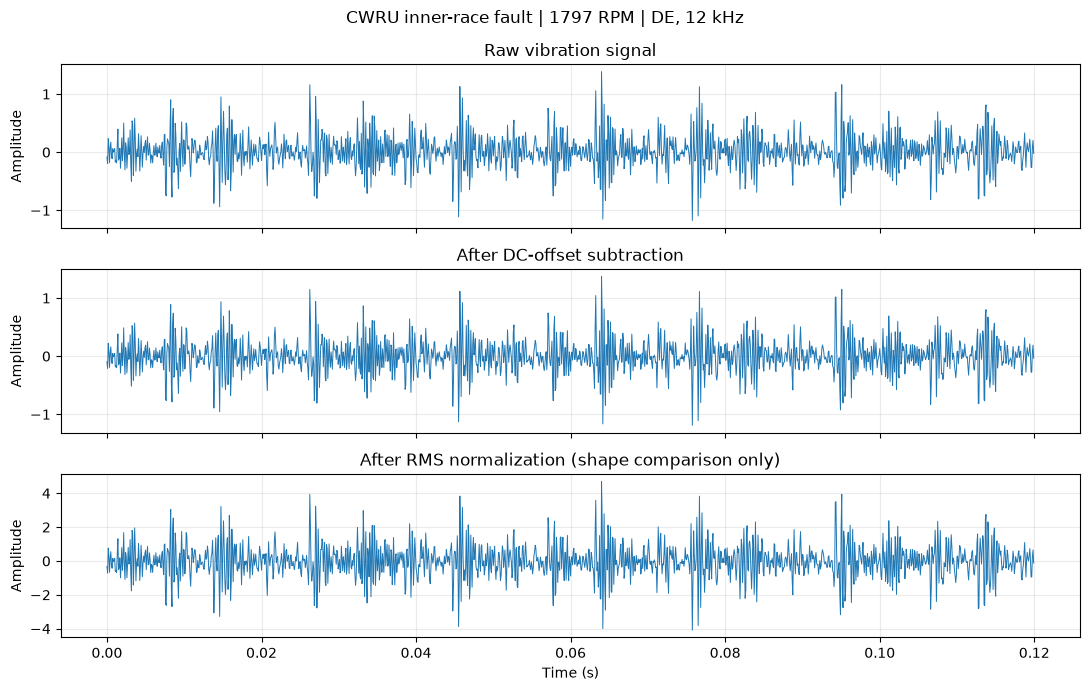

Preprocessing statistics: {'dc_offset': 0.013443559443270718, 'rms': 0.29121590933470093, 'peak': 1.7255869395587253}


In [8]:
representative = records_by_fault["Inner Race"][1797]
x_raw = representative["signal"]
x_demeaned, x_rms_normalized, representative_stats = preprocess_signal(x_raw)

n_plot = int(0.12 * SAMPLING_RATE_HZ)
time_axis = np.arange(n_plot) / SAMPLING_RATE_HZ

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(time_axis, x_raw[:n_plot], linewidth=0.7)
axes[0].set_title("Raw vibration signal")
axes[1].plot(time_axis, x_demeaned[:n_plot], linewidth=0.7)
axes[1].set_title("After DC-offset subtraction")
axes[2].plot(time_axis, x_rms_normalized[:n_plot], linewidth=0.7)
axes[2].set_title("After RMS normalization (shape comparison only)")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.25)
fig.suptitle("CWRU inner-race fault | 1797 RPM | DE, 12 kHz")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A1_CWRU_preprocessing.png", dpi=250, bbox_inches="tight")
plt.show()
print("Preprocessing statistics:", representative_stats)

## 10. Baseline FFT of the representative CWRU record

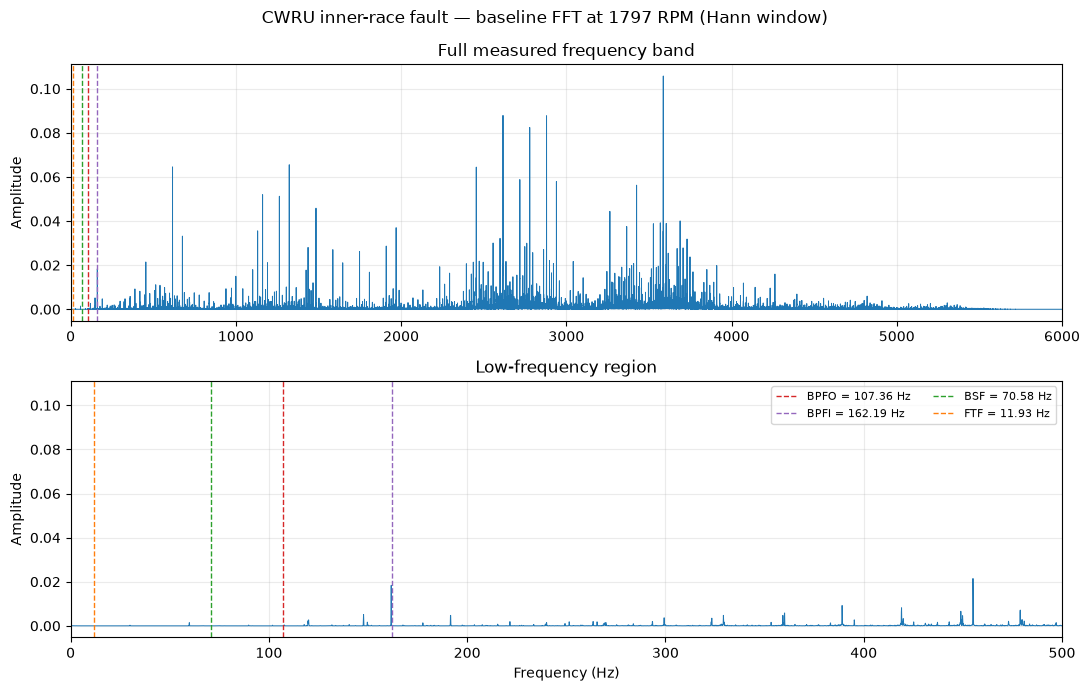

In [9]:
frequencies, amplitude = single_sided_amplitude_spectrum(
    x_demeaned, SAMPLING_RATE_HZ, window="hann"
)
reference_freqs = kinematic_fault_frequencies(1797)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(frequencies, amplitude, linewidth=0.7)
axes[0].set_xlim(0, SAMPLING_RATE_HZ / 2)
axes[0].set_title("Full measured frequency band")
axes[0].set_ylabel("Amplitude")
axes[1].plot(frequencies, amplitude, linewidth=0.7)
axes[1].set_xlim(0, 500)
axes[1].set_title("Low-frequency region")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Amplitude")
colors = {"BPFO_Hz": "tab:red", "BPFI_Hz": "tab:purple", "BSF_Hz": "tab:green", "FTF_Hz": "tab:orange"}
for name, value in reference_freqs.items():
    if name in colors:
        for ax in axes:
            if value <= ax.get_xlim()[1]:
                ax.axvline(value, linestyle="--", linewidth=1, color=colors[name], label=f"{name.replace('_Hz','')} = {value:.2f} Hz")
axes[1].legend(fontsize=8, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("CWRU inner-race fault — baseline FFT at 1797 RPM (Hann window)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A2_CWRU_baseline_FFT.png", dpi=250, bbox_inches="tight")
plt.show()

The dashed lines indicate ideal kinematic reference frequencies. The baseline FFT shows the measured raw spectrum; it should not be treated as a completed fault detector. A weak defect repetition component can be obscured by other vibration components, motivating the later resonance selection and envelope demodulation stages.

## 11. Spectral leakage: window comparison

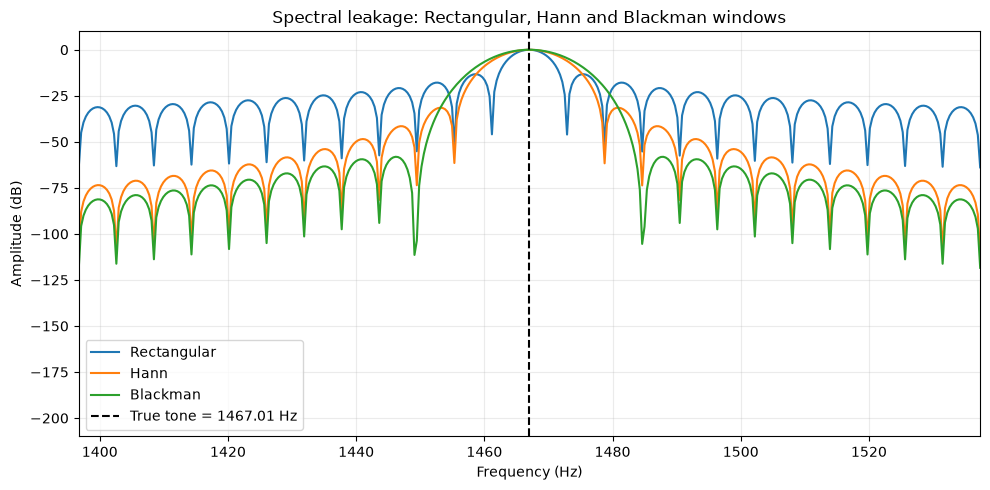

,Window,Approx_Leakage_Energy_Fraction
0,Rectangular,0.066135
1,Hann,0.000176
2,Blackman,0.000003


In [10]:
# Controlled off-bin sinusoid used only to demonstrate the effect of finite-window leakage.
fs_demo = 12_000.0
n_demo = 2048
tone_bin = 250
fractional_offset = 0.37
f0 = (tone_bin + fractional_offset) * fs_demo / n_demo
n = np.arange(n_demo)
x_tone = np.sin(2 * np.pi * f0 * n / fs_demo)

leakage_rows = []
fig, ax = plt.subplots(figsize=(10, 5))
for window in WINDOWS:
    f, a = single_sided_amplitude_spectrum(
        x_tone, fs_demo, window=window, nfft=n_demo * 16
    )
    ax.plot(f, 20 * np.log10(np.maximum(a, 1e-10)), label=WINDOW_LABELS[window])

    half_widths = {"boxcar": 1.5, "hann": 2.5, "blackman": 3.5}
    peak = int(np.argmax(a))
    half = int(np.ceil(half_widths[window] * 16))
    mask = np.zeros(a.size, dtype=bool)
    mask[max(0, peak-half):min(a.size, peak+half+1)] = True
    energy = a**2
    leakage_rows.append({
        "Window": WINDOW_LABELS[window],
        "Approx_Leakage_Energy_Fraction": float(np.sum(energy[~mask]) / np.sum(energy)),
    })

ax.axvline(f0, color="black", linestyle="--", label=f"True tone = {f0:.2f} Hz")
ax.set_xlim(f0 - 12 * fs_demo / n_demo, f0 + 12 * fs_demo / n_demo)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude (dB)")
ax.set_title("Spectral leakage: Rectangular, Hann and Blackman windows")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A3_spectral_leakage_windows.png", dpi=250, bbox_inches="tight")
plt.show()

display(pd.DataFrame(leakage_rows).round(8))

The leakage graph is a **controlled synthetic demonstration**, not a bearing measurement. It isolates how the observation window changes sidelobes and main lobe width. The reported leakage fraction is an approximate educational metric based on excluding a window specific main lobe region.

## 12. STFT comparison for the representative CWRU record

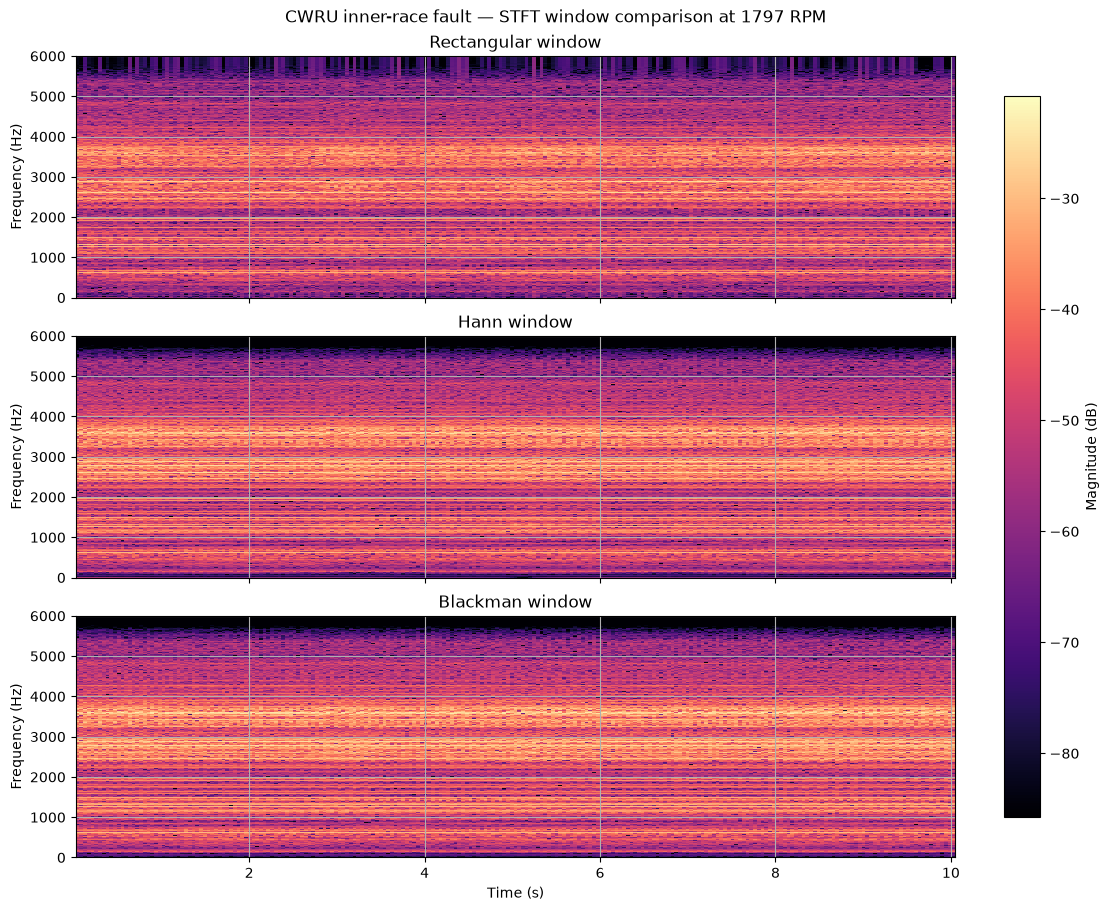

In [11]:
stft_results = []
for window in WINDOWS:
    f, t_stft, z = compute_stft(
        x_demeaned, SAMPLING_RATE_HZ,
        window=window, nperseg=1024, noverlap=512
    )
    magnitude_db = 20 * np.log10(np.maximum(np.abs(z), 1e-12))
    stft_results.append((window, f, t_stft, magnitude_db))

shared_max = max(float(np.max(item[3])) for item in stft_results)
vmin, vmax = shared_max - 65, shared_max
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True, constrained_layout=True)
mesh = None
for ax, (window, f, t_stft, magnitude_db) in zip(axes, stft_results):
    mesh = ax.pcolormesh(
        t_stft, f, magnitude_db, shading="auto", cmap="magma",
        vmin=vmin, vmax=vmax
    )
    ax.set_ylim(0, SAMPLING_RATE_HZ / 2)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{WINDOW_LABELS[window]} window")
axes[-1].set_xlabel("Time (s)")
fig.colorbar(mesh, ax=axes, label="Magnitude (dB)", shrink=0.9)
fig.suptitle("CWRU inner-race fault — STFT window comparison at 1797 RPM")
fig.savefig(OUTPUT_DIR / "A4_CWRU_STFT_windows.png", dpi=250, bbox_inches="tight")
plt.show()

## 13. Inner-race FFT across four motor loads

The same 7 mil inner race defect and DE12 channel are compared at 0, 1, 2 and 3 HP. Dashed lines mark the theoretical BPFI for each shaft speed.

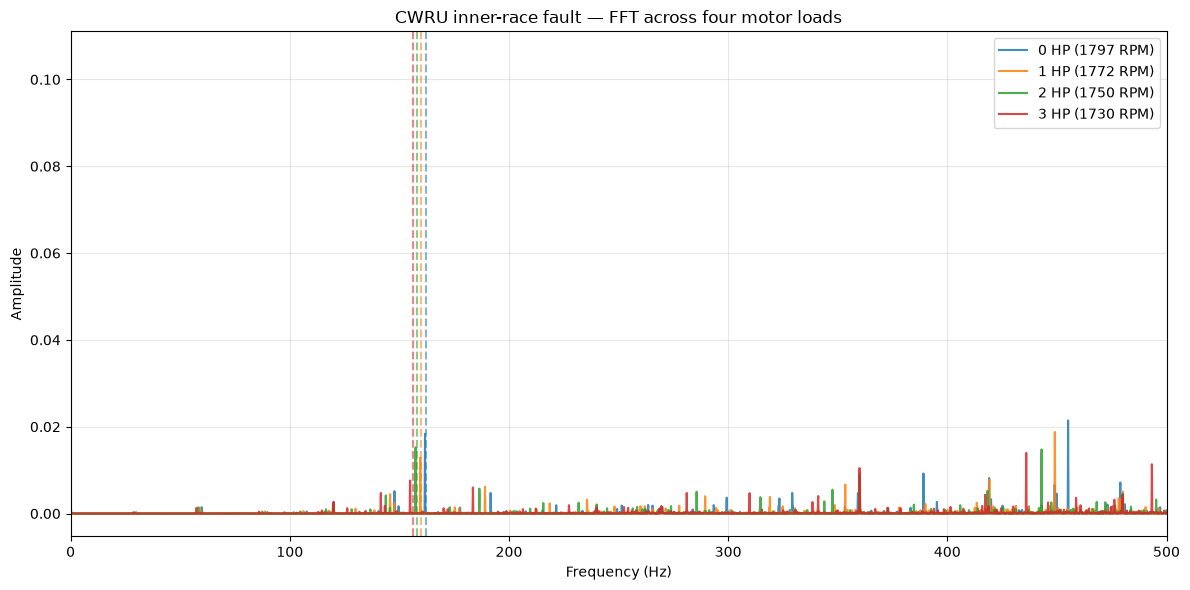

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
for rpm in RPM_VALUES:
    rec = records_by_fault["Inner Race"][rpm]
    x, _, _ = preprocess_signal(rec["signal"])
    f, a = single_sided_amplitude_spectrum(x, SAMPLING_RATE_HZ, window="hann")
    line, = ax.plot(f, a, label=f"{rec['load_hp']} HP ({rpm} RPM)", alpha=0.85)
    bpfi = kinematic_fault_frequencies(rpm)["BPFI_Hz"]
    ax.axvline(bpfi, color=line.get_color(), linestyle="--", alpha=0.55)

ax.set_xlim(0, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude")
ax.set_title("CWRU inner-race fault — FFT across four motor loads")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A5_CWRU_inner_race_FFT_four_loads.png", dpi=250, bbox_inches="tight")
plt.show()

## 14. FFT comparison across three fault types and four loads

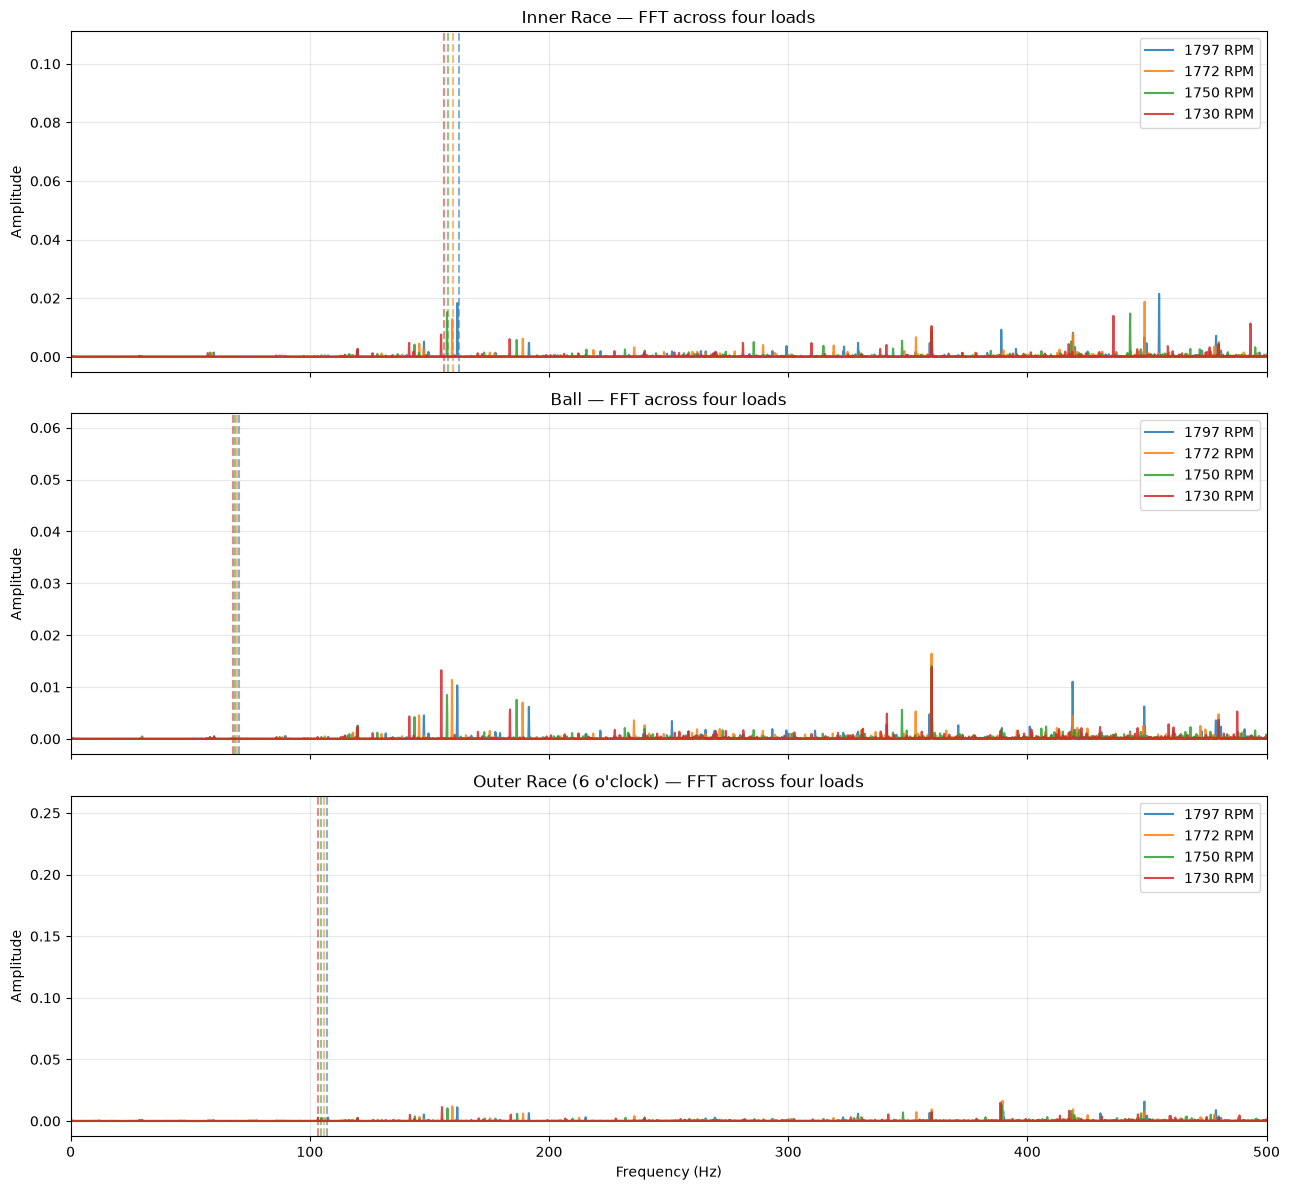

In [13]:
fault_frequency_key = {
    "Inner Race": "BPFI_Hz",
    "Ball": "BSF_Hz",
    "Outer Race (6 o'clock)": "BPFO_Hz",
}

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, (fault_name, fault_records) in zip(axes, records_by_fault.items()):
    target_key = fault_frequency_key[fault_name]
    for rpm in RPM_VALUES:
        rec = fault_records[rpm]
        x, _, _ = preprocess_signal(rec["signal"])
        f, a = single_sided_amplitude_spectrum(x, SAMPLING_RATE_HZ, window="hann")
        line, = ax.plot(f, a, label=f"{rpm} RPM", alpha=0.85)
        target = kinematic_fault_frequencies(rpm)[target_key]
        ax.axvline(target, color=line.get_color(), linestyle="--", alpha=0.55)
    ax.set_xlim(0, 500)
    ax.set_ylabel("Amplitude")
    ax.set_title(f"{fault_name} — FFT across four loads")
    ax.legend()
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Frequency (Hz)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A6_CWRU_three_faults_four_loads.png", dpi=250, bbox_inches="tight")
plt.show()

## 15. Experimental summary table

In [14]:
fault_frequency_key = {
    "Inner Race": "BPFI_Hz",
    "Ball": "BSF_Hz",
    "Outer Race (6 o'clock)": "BPFO_Hz",
}

result_rows = []
for fault_name, fault_records in records_by_fault.items():
    for rpm, rec in fault_records.items():
        x, _, stats = preprocess_signal(rec["signal"])
        characteristic = kinematic_fault_frequencies(rpm)
        target_key = fault_frequency_key[fault_name]
        result_rows.append({
            "Fault": fault_name,
            "Load_HP": rec["load_hp"],
            "RPM": rpm,
            "Samples": len(x),
            "Sampling_Rate_Hz": SAMPLING_RATE_HZ,
            "Duration_s": len(x) / SAMPLING_RATE_HZ,
            "DC_Offset": stats["dc_offset"],
            "RMS": stats["rms"],
            "Peak": stats["peak"],
            "BPFO_Hz": characteristic["BPFO_Hz"],
            "BPFI_Hz": characteristic["BPFI_Hz"],
            "BSF_Hz": characteristic["BSF_Hz"],
            "FTF_Hz": characteristic["FTF_Hz"],
            "Target_Fault_Frequency_Hz": characteristic[target_key],
        })

cwru_results_df = pd.DataFrame(result_rows).sort_values(["Fault", "Load_HP"])
display(cwru_results_df.round(4))

,Fault,Load_HP,RPM,Samples,Sampling_Rate_Hz,Duration_s,DC_Offset,RMS,Peak,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz,Target_Fault_Frequency_Hz
4,Ball,0,1797,122571,12000.0,10.2142,0.0126,0.1387,0.6196,107.3643,162.1857,70.5846,11.9294,70.5846
5,Ball,1,1772,121410,12000.0,10.1175,0.0039,0.1390,0.6635,105.8706,159.9294,69.6026,11.7634,69.6026
6,Ball,2,1750,121556,12000.0,10.1297,0.0046,0.1472,0.6000,104.5562,157.9438,68.7385,11.6174,68.7385
7,Ball,3,1730,121556,12000.0,10.1297,0.0042,0.1536,0.7248,103.3613,156.1387,67.9529,11.4846,67.9529
0,Inner Race,0,1797,121265,12000.0,10.1054,0.0134,0.2912,1.7256,107.3643,162.1857,70.5846,11.9294,162.1857
1,Inner Race,1,1772,121991,12000.0,10.1659,0.0058,0.2928,1.5750,105.8706,159.9294,69.6026,11.7634,159.9294
2,Inner Race,2,1750,122136,12000.0,10.1780,0.0046,0.2995,1.6351,104.5562,157.9438,68.7385,11.6174,157.9438
3,Inner Race,3,1730,122917,12000.0,10.2431,0.0047,0.3136,1.6667,103.3613,156.1387,67.9529,11.4846,156.1387
8,Outer Race (6 o'clock),0,1797,121991,12000.0,10.1659,0.0232,0.6691,3.6073,107.3643,162.1857,70.5846,11.9294,107.3643
9,Outer Race (6 o'clock),1,1772,122426,12000.0,10.2022,0.0041,0.5919,3.1082,105.8706,159.9294,69.6026,11.7634,105.8706


## 16. RMS vibration amplitude across motor loads

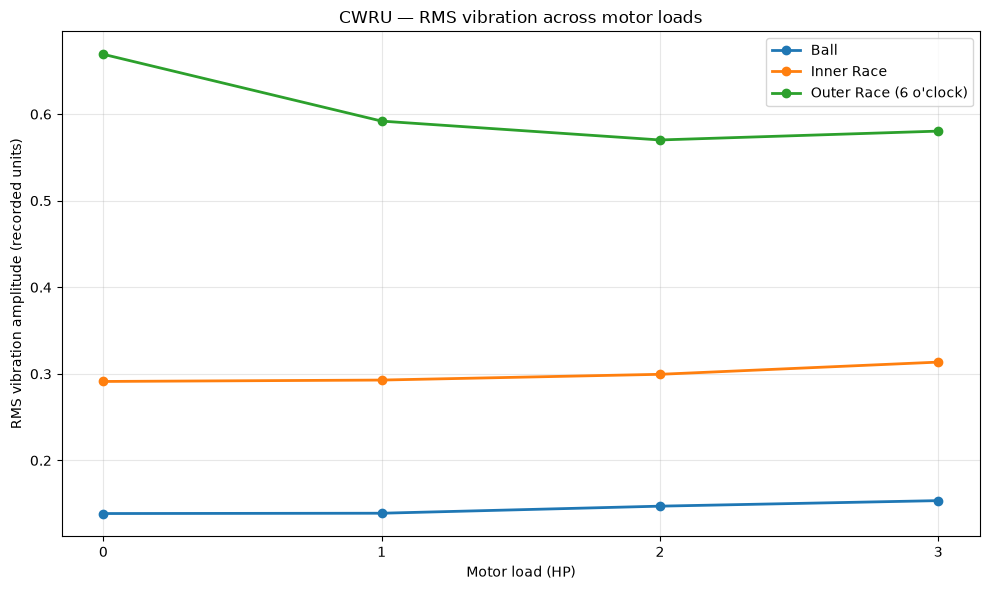

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
for fault_name in cwru_results_df["Fault"].unique():
    subset = cwru_results_df[cwru_results_df["Fault"] == fault_name].sort_values("Load_HP")
    ax.plot(
        subset["Load_HP"], subset["RMS"],
        marker="o", linewidth=2, label=fault_name
    )

ax.set_xlabel("Motor load (HP)")
ax.set_ylabel("RMS vibration amplitude (recorded units)")
ax.set_title("CWRU — RMS vibration across motor loads")
ax.set_xticks([0, 1, 2, 3])
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A7_CWRU_RMS_vs_load.png", dpi=250, bbox_inches="tight")
plt.show()

## 17. Export tables and figures



In [16]:
cwru_inventory_csv = OUTPUT_DIR / "CWRU_dataset_inventory.csv"
selected_metadata_csv = OUTPUT_DIR / "CWRU_selected_record_metadata.csv"
frequency_csv = OUTPUT_DIR / "CWRU_kinematic_frequency_table.csv"
results_csv = OUTPUT_DIR / "CWRU_experimental_results.csv"
leakage_csv = OUTPUT_DIR / "CWRU_window_leakage_metrics.csv"

cwru_inventory.to_csv(cwru_inventory_csv, index=False)
cwru_metadata_df.to_csv(selected_metadata_csv, index=False)
cwru_frequency_table.to_csv(frequency_csv, index=False)
cwru_results_df.to_csv(results_csv, index=False)
pd.DataFrame(leakage_rows).to_csv(leakage_csv, index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

Saved files:
A1_CWRU_preprocessing.png: 706,977 bytes
A2_CWRU_baseline_FFT.png: 221,299 bytes
A3_spectral_leakage_windows.png: 301,024 bytes
A4_CWRU_STFT_windows.png: 1,568,812 bytes
A5_CWRU_inner_race_FFT_four_loads.png: 164,411 bytes
A6_CWRU_three_faults_four_loads.png: 382,450 bytes
A7_CWRU_RMS_vs_load.png: 110,645 bytes
CWRU_dataset_inventory.csv: 17,624 bytes
CWRU_experimental_results.csv: 2,545 bytes
CWRU_kinematic_frequency_table.csv: 481 bytes
CWRU_selected_record_metadata.csv: 889 bytes
CWRU_window_leakage_metrics.csv: 129 bytes


> **Note — MFPT data.** The 17 MFPT recordings ship as `datasets/MPFT.zip` and are
> extracted to `datasets/MFPT/` on first run. The MFPT helper functions are defined
> inside the next code cell, so this notebook is self-contained and only the `.ipynb`
> file needs to be uploaded. If the archive is missing (for example on a fresh Colab
> session), the block falls back to a ZIP upload. Nothing after this section depends
> on it.


# MFPT Bearing Dataset Analysis  Member 1 - Vidyashankar T


### Report figures generated
1. **Fig. B1:** Inner race FFT across the available radial loads.
2. **Fig. B2:** Outer race FFT across the available radial loads.
3. **Fig. B3:** RMS vibration amplitude across radial loads, with the healthy baseline reference.


### Supplied dataset
- 3 healthy baseline records: 270 lb, 97.656 kHz, 6 s each.
- 7 inner-race records: 0, 50, 100, 150, 200, 250, and 300 lb; 48.828 kHz, 3 s each.
- 7 outer-race records: 25, 50, 100, 150, 200, 250, and 300 lb; 48.828 kHz, 3 s each.

## 1. Environment and MFPT input files


In [17]:
from pathlib import Path
import os
import shutil
import zipfile
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy import signal
from IPython.display import display

%matplotlib inline

# ---------------------------------------------------------------------
# Input files: use datasets/MFPT when present (auto-extracted from the
# bundled archive on first run); otherwise fall back to a Google Colab upload.
# ---------------------------------------------------------------------
# Resolve the project root so the block also works when Jupyter starts inside code/.
PROJECT_ROOT = Path.cwd() if any((Path.cwd() / name).exists() for name in ("code", "datasets")) else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "datasets/MFPT"
BUNDLED_ARCHIVE = PROJECT_ROOT / "datasets/MPFT.zip"


def _extract_archives(archives):
    """Extract every MFPT archive into DATA_DIR, keeping the archive folder layout."""
    for archive in archives:
        archive = Path(archive)
        if not archive.exists():
            raise FileNotFoundError(archive)
        with zipfile.ZipFile(archive, "r") as zf:
            bad_file = zf.testzip()
            if bad_file:
                raise ValueError(f"Corrupted file {bad_file} in {archive.name}")
            zf.extractall(DATA_DIR)
        print("Extracted:", archive.name)


def ensure_mfpt_data():
    """Return the folder holding the 17 .mat recordings, extracting or uploading when needed."""
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if any(DATA_DIR.rglob("*.mat")):
        return DATA_DIR

    if BUNDLED_ARCHIVE.exists():
        _extract_archives([BUNDLED_ARCHIVE])
        return DATA_DIR

    local_archives = sorted(Path(".").glob("MFPT_Input_*.zip"))
    if local_archives:
        _extract_archives(local_archives)
        return DATA_DIR

    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "MFPT recordings not found: place MPFT.zip in datasets/ or the 17 .mat files in datasets/MFPT/."
        ) from exc

    uploaded = files.upload()
    archives = [Path(name) for name in uploaded if name.lower().endswith(".zip")]
    if not archives:
        raise ValueError("Upload at least one ZIP archive that contains the MFPT .mat recordings.")
    _extract_archives(archives)
    return DATA_DIR


MFPT_ROOT = ensure_mfpt_data()

# ---------------------------------------------------------------------
# MFPT helpers (inlined, so the notebook is a single self-contained file)
# ---------------------------------------------------------------------
MFPT_NICE = SimpleNamespace(
    n_balls=8,
    ball_diameter_in=0.235,
    pitch_diameter_in=1.245,
    contact_angle_deg=0.0,
)


def mfpt_kinematic_fault_frequencies(shaft_rate_hz, geometry=MFPT_NICE):
    """Return BPFO, BPFI, BSF and FTF in Hz at the given shaft speed."""
    shaft_rate_hz = float(shaft_rate_hz)
    if not np.isfinite(shaft_rate_hz) or shaft_rate_hz <= 0:
        raise ValueError("Shaft rate must be a positive finite value.")

    ratio = (geometry.ball_diameter_in / geometry.pitch_diameter_in) * np.cos(
        np.deg2rad(geometry.contact_angle_deg)
    )
    n = geometry.n_balls
    return {
        "shaft_rate_Hz": shaft_rate_hz,
        "shaft_rpm": 60.0 * shaft_rate_hz,
        "BPFO_Hz": (n / 2) * shaft_rate_hz * (1 - ratio),
        "BPFI_Hz": (n / 2) * shaft_rate_hz * (1 + ratio),
        "BSF_Hz": (geometry.pitch_diameter_in / (2 * geometry.ball_diameter_in))
        * shaft_rate_hz
        * (1 - ratio**2),
        "FTF_Hz": (shaft_rate_hz / 2) * (1 - ratio),
    }


def load_mfpt_mat(path):
    """Load one MFPT recording and attach its fault class and operating point."""
    path = str(path)
    if not os.path.exists(path):
        raise FileNotFoundError(path)

    data = sio.loadmat(path, squeeze_me=True, struct_as_record=False)

    if "bearing" not in data:
        raise KeyError(f"No 'bearing' struct in {os.path.basename(path)}")

    bearing = data["bearing"]
    x = np.asarray(bearing.gs, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16 or not np.all(np.isfinite(x)):
        raise ValueError(f"Invalid signal array in {os.path.basename(path)}: shape={x.shape}")

    sampling_rate = float(bearing.sr)
    shaft_rate_hz = float(bearing.rate)
    load_lbs = float(bearing.load)

    name = os.path.basename(path).lower()
    if name.startswith("baseline"):
        fault = "Normal"
    elif name.startswith("innerracefault"):
        fault = "Inner race"
    elif name.startswith("outerracefault"):
        fault = "Outer race"
    else:
        raise ValueError(f"Unrecognized MFPT filename: {name}")

    return SimpleNamespace(
        signal=x,
        sampling_rate=sampling_rate,
        duration_seconds=x.size / sampling_rate,
        metadata={
            "fault": fault,
            "load_lbs": load_lbs,
            "shaft_rate_hz": shaft_rate_hz,
            "shaft_rpm": 60.0 * shaft_rate_hz,
        },
    )


def mfpt_preprocess_signal(x, normalization="none"):
    """Remove the DC mean and optionally normalize by RMS or peak amplitude."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16 or not np.all(np.isfinite(x)):
        raise ValueError("Expected a finite one-dimensional signal of at least 16 samples.")

    dc_offset = float(np.mean(x))
    demeaned = x - dc_offset
    rms = float(np.sqrt(np.mean(demeaned**2)))
    peak = float(np.max(np.abs(demeaned)))

    if normalization == "none":
        normalized = demeaned.copy()
    elif normalization == "rms":
        normalized = demeaned / rms if rms > np.finfo(float).eps else demeaned.copy()
    elif normalization == "peak":
        normalized = demeaned / peak if peak > np.finfo(float).eps else demeaned.copy()
    else:
        raise ValueError(f"normalization must be 'none', 'rms' or 'peak', got {normalization!r}")

    stats = {
        "dc_offset": dc_offset,
        "rms_before_normalization": rms,
        "peak_before_normalization": peak,
    }
    return demeaned, normalized, stats


def mfpt_single_sided_spectrum(x, fs, window="hann"):
    """Coherent-gain-corrected one-sided amplitude spectrum."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16:
        raise ValueError("Expected a one-dimensional signal with at least 16 samples.")

    x = x - np.mean(x)
    w = signal.get_window(window, x.size, fftbins=True)
    scale = np.sum(w)
    if scale <= np.finfo(float).eps:
        raise ValueError("Window coherent gain is zero.")

    spectrum = np.abs(np.fft.rfft(x * w)) / scale
    if spectrum.size > 2:
        spectrum[1:-1] *= 2.0

    frequencies = np.fft.rfftfreq(x.size, d=1.0 / float(fs))
    return frequencies, spectrum

print("\nMFPT dataset setup completed!")
print("Dataset folder:", MFPT_ROOT.resolve())



MFPT dataset setup completed!
Dataset folder: /home/darshan/DLA/dspminiproject/datasets/MFPT


## 2. Load and validate the 17 MFPT recordings

Each file is loaded using its MATLAB metadata. Any failed file is reported explicitly.

In [18]:
mfpt_paths = sorted(
    [p for p in MFPT_ROOT.rglob("*.mat")
     if p.name.lower().startswith(("baseline_", "innerracefault_", "outerracefault_"))],
    key=lambda p: p.name.lower()
)

print("MATLAB recordings found:", len(mfpt_paths))
if len(mfpt_paths) != 17:
    raise RuntimeError(f"Expected 17 recordings in the supplied dataset, found {len(mfpt_paths)}.")

mfpt_records = {}
load_errors = []
for path in mfpt_paths:
    try:
        rec = load_mfpt_mat(str(path))
        mfpt_records[path.name] = rec
    except Exception as exc:
        load_errors.append({"Filename": path.name, "Error": repr(exc)})

if load_errors:
    display(pd.DataFrame(load_errors))
    raise RuntimeError(f"{len(load_errors)} MFPT file(s) failed to load.")

print("Successfully loaded:", len(mfpt_records))

MATLAB recordings found: 17


Successfully loaded: 17


## 3. Recording metadata and load coverage

RMS and peak are calculated after removing the sample mean. They describe signal amplitude, they are not fault detection metrics.

In [19]:
metadata_rows = []
for filename, rec in mfpt_records.items():
    x_demeaned, _, stats = mfpt_preprocess_signal(rec.signal, normalization="none")
    metadata_rows.append({
        "Filename": filename,
        "Fault": rec.metadata["fault"],
        "Load_lb": float(rec.metadata["load_lbs"]),
        "Shaft_Rate_Hz": float(rec.metadata["shaft_rate_hz"]),
        "Shaft_RPM": float(rec.metadata["shaft_rpm"]),
        "Sampling_Rate_Hz": float(rec.sampling_rate),
        "Samples": int(len(rec.signal)),
        "Duration_s": float(rec.duration_seconds),
        "RMS_Demeaned": float(stats["rms_before_normalization"]),
        "Peak_Demeaned": float(stats["peak_before_normalization"]),
    })

mfpt_summary_df = pd.DataFrame(metadata_rows).sort_values(
    ["Fault", "Load_lb", "Filename"]
).reset_index(drop=True)

display(mfpt_summary_df.round(4))

coverage = (mfpt_summary_df.groupby(["Fault", "Sampling_Rate_Hz", "Duration_s"])
            .agg(Recordings=("Filename", "count"),
                 Loads_lb=("Load_lb", lambda s: ", ".join(f"{v:g}" for v in sorted(s))))
            .reset_index())
display(coverage)

expected_counts = {"Normal": 3, "Inner race": 7, "Outer race": 7}
actual_counts = mfpt_summary_df["Fault"].value_counts().to_dict()
if actual_counts != expected_counts:
    raise RuntimeError(f"Unexpected fault-class counts: {actual_counts}; expected {expected_counts}.")

,Filename,Fault,Load_lb,Shaft_Rate_Hz,Shaft_RPM,Sampling_Rate_Hz,Samples,Duration_s,RMS_Demeaned,Peak_Demeaned
0,InnerRaceFault_vload_1.mat,Inner race,0.0,25.0,1500.0,48828.0,146484,3.0,1.7999,45.7439
1,InnerRaceFault_vload_2.mat,Inner race,50.0,25.0,1500.0,48828.0,146484,3.0,1.7643,27.7217
2,InnerRaceFault_vload_3.mat,Inner race,100.0,25.0,1500.0,48828.0,146484,3.0,1.8217,26.3663
3,InnerRaceFault_vload_4.mat,Inner race,150.0,25.0,1500.0,48828.0,146484,3.0,1.7267,23.2772
4,InnerRaceFault_vload_5.mat,Inner race,200.0,25.0,1500.0,48828.0,146484,3.0,2.0117,27.5919
5,InnerRaceFault_vload_6.mat,Inner race,250.0,25.0,1500.0,48828.0,146484,3.0,2.0745,27.3439
6,InnerRaceFault_vload_7.mat,Inner race,300.0,25.0,1500.0,48828.0,146484,3.0,1.9590,25.3924
7,baseline_1.mat,Normal,270.0,25.0,1500.0,97656.0,585936,6.0,0.8796,4.5123
8,baseline_2.mat,Normal,270.0,25.0,1500.0,97656.0,585936,6.0,0.8670,4.3744
9,baseline_3.mat,Normal,270.0,25.0,1500.0,97656.0,585936,6.0,0.8743,4.2767


,Fault,Sampling_Rate_Hz,Duration_s,Recordings,Loads_lb
0,Inner race,48828.0,3.0,7,"0, 50, 100, 150, 200, 250, 300"
1,Normal,97656.0,6.0,3,"270, 270, 270"
2,Outer race,48828.0,3.0,7,"25, 50, 100, 150, 200, 250, 300"


## 4. Theoretical MFPT characteristic frequencies

The supplied recordings report a shaft rate of 25 Hz (1500 RPM). The following frequencies are ideal geometry based references calculated using the MFPT bearing geometry defined in the project module. Measured spectral peaks may differ slightly because of slip and other operating effects.

In [20]:
shaft_rates = sorted(mfpt_summary_df["Shaft_Rate_Hz"].dropna().unique())
frequency_rows = []
for shaft_rate in shaft_rates:
    f = mfpt_kinematic_fault_frequencies(
        shaft_rate_hz=float(shaft_rate),
        geometry=MFPT_NICE
    )
    frequency_rows.append({
        "Shaft_Rate_Hz": f["shaft_rate_Hz"],
        "Shaft_RPM": f["shaft_rpm"],
        "BPFO_Hz": f["BPFO_Hz"],
        "BPFI_Hz": f["BPFI_Hz"],
        "BSF_Hz": f["BSF_Hz"],
        "FTF_Hz": f["FTF_Hz"],
    })

mfpt_frequency_table = pd.DataFrame(frequency_rows)
display(mfpt_frequency_table.round(4))

if not np.allclose(mfpt_summary_df["Shaft_Rate_Hz"], 25.0):
    raise ValueError("The supplied files do not all report the expected 25 Hz shaft rate. Review the metadata before plotting.")

,Shaft_Rate_Hz,Shaft_RPM,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz
0,25.0,1500.0,81.1245,118.8755,63.864,10.1406


## 5. Prepare variable load fault groups

The inner and outer race variable load files use 48.828 kHz and 3 second records. The healthy baseline repeats use 97.656 kHz and 6 second records and are not mixed into the FFT overlays.

In [21]:
mfpt_baseline = {
    name: rec for name, rec in mfpt_records.items()
    if rec.metadata["fault"] == "Normal"
}

inner_variable = {
    name: rec for name, rec in mfpt_records.items()
    if rec.metadata["fault"] == "Inner race"
    and np.isclose(rec.sampling_rate, 48828, atol=1)
}

outer_variable = {
    name: rec for name, rec in mfpt_records.items()
    if rec.metadata["fault"] == "Outer race"
    and np.isclose(rec.sampling_rate, 48828, atol=1)
}

def sorted_by_load(record_dict):
    return sorted(record_dict.items(), key=lambda item: float(item[1].metadata["load_lbs"]))

print("Healthy baseline repeats:", len(mfpt_baseline))
print("Inner-race variable-load records:", len(inner_variable))
print("Outer-race variable-load records:", len(outer_variable))
print("Inner-race loads:", [float(r.metadata["load_lbs"]) for _, r in sorted_by_load(inner_variable)])
print("Outer-race loads:", [float(r.metadata["load_lbs"]) for _, r in sorted_by_load(outer_variable)])

if len(mfpt_baseline) != 3 or len(inner_variable) != 7 or len(outer_variable) != 7:
    raise RuntimeError("The supplied records do not match the expected MFPT condition coverage.")

Healthy baseline repeats: 3
Inner-race variable-load records: 7
Outer-race variable-load records: 7
Inner-race loads: [0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0]
Outer-race loads: [25.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0]


## 6. Fig. B1 MFPT inner race FFT across radial loads

Each curve is the single sided Hann window amplitude spectrum of a mean removed, 3 second vibration record. The vertical line marks the ideal BPFI. Curves retain the signal's original amplitude scale, they are not RMS normalized.

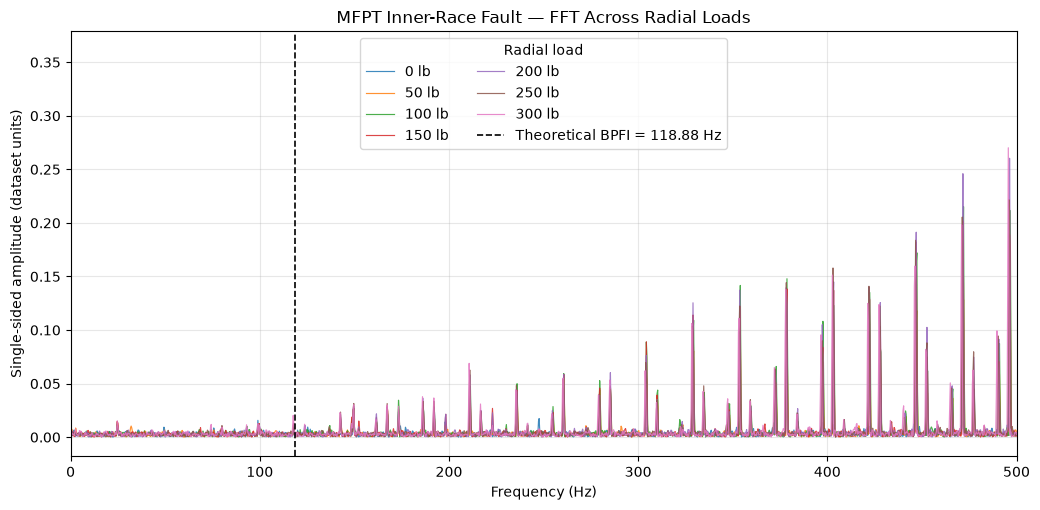

In [22]:
OUTPUT_DIR = Path("MFPT_Report_Outputs")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for filename, rec in sorted_by_load(inner_variable):
    x_demeaned, _, _ = mfpt_preprocess_signal(rec.signal, normalization="none")
    freqs, amp = mfpt_single_sided_spectrum(
        x_demeaned, rec.sampling_rate, window="hann"
    )
    load = float(rec.metadata["load_lbs"])
    ax.plot(freqs, amp, linewidth=0.85, alpha=0.85, label=f"{load:g} lb")

shaft_rate = float(next(iter(inner_variable.values())).metadata["shaft_rate_hz"])
bpfi = mfpt_kinematic_fault_frequencies(shaft_rate_hz=shaft_rate, geometry=MFPT_NICE)["BPFI_Hz"]
ax.axvline(bpfi, color="black", linestyle="--", linewidth=1.2,
           label=f"Theoretical BPFI = {bpfi:.2f} Hz")
ax.set_xlim(0, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Single-sided amplitude (dataset units)")
ax.set_title("MFPT Inner-Race Fault — FFT Across Radial Loads")
ax.legend(title="Radial load", ncols=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "Fig_B1_MFPT_Inner_Race_FFT_Loads.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Fig. B2  MFPT outer race FFT across radial loads

The outer race series begins at 25 lb, unlike the inner race series, the supplied MFPT files contain no 0 lb outer-race record. The vertical line marks the ideal BPFO.

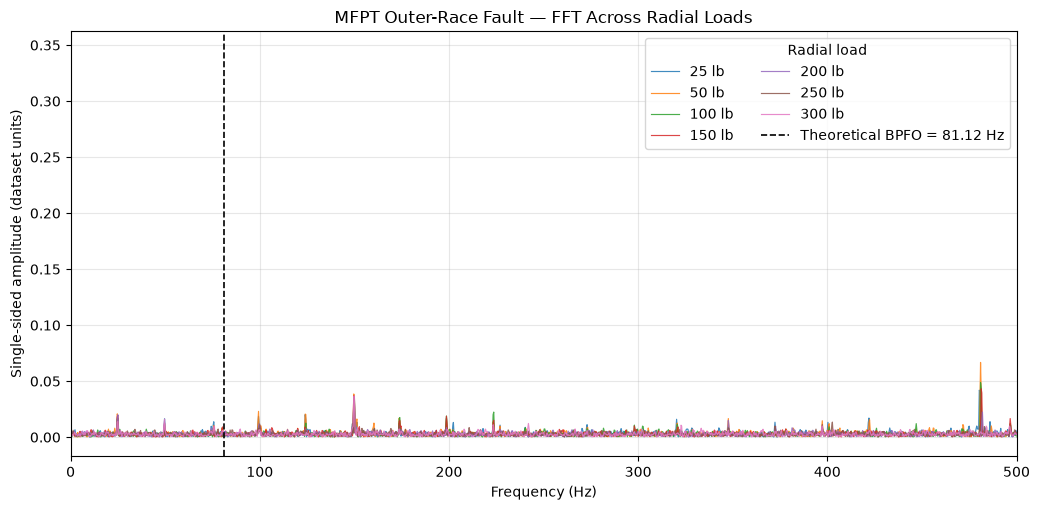

In [23]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for filename, rec in sorted_by_load(outer_variable):
    x_demeaned, _, _ = mfpt_preprocess_signal(rec.signal, normalization="none")
    freqs, amp = mfpt_single_sided_spectrum(
        x_demeaned, rec.sampling_rate, window="hann"
    )
    load = float(rec.metadata["load_lbs"])
    ax.plot(freqs, amp, linewidth=0.85, alpha=0.85, label=f"{load:g} lb")

shaft_rate = float(next(iter(outer_variable.values())).metadata["shaft_rate_hz"])
bpfo = mfpt_kinematic_fault_frequencies(shaft_rate_hz=shaft_rate, geometry=MFPT_NICE)["BPFO_Hz"]
ax.axvline(bpfo, color="black", linestyle="--", linewidth=1.2,
           label=f"Theoretical BPFO = {bpfo:.2f} Hz")
ax.set_xlim(0, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Single-sided amplitude (dataset units)")
ax.set_title("MFPT Outer-Race Fault — FFT Across Radial Loads")
ax.legend(title="Radial load", ncols=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "Fig_B2_MFPT_Outer_Race_FFT_Loads.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Fig. B3 RMS vibration amplitude across radial loads

RMS is calculated after subtracting the sample mean. The three healthy baseline recordings are repeated measurements at 270 lb, 97.656 kHz, and 6 s. Their mean and sample standard deviation are shown as a separate reference marker. The healthy reference is not a healthy load sweep and is not connected to the fault curves.

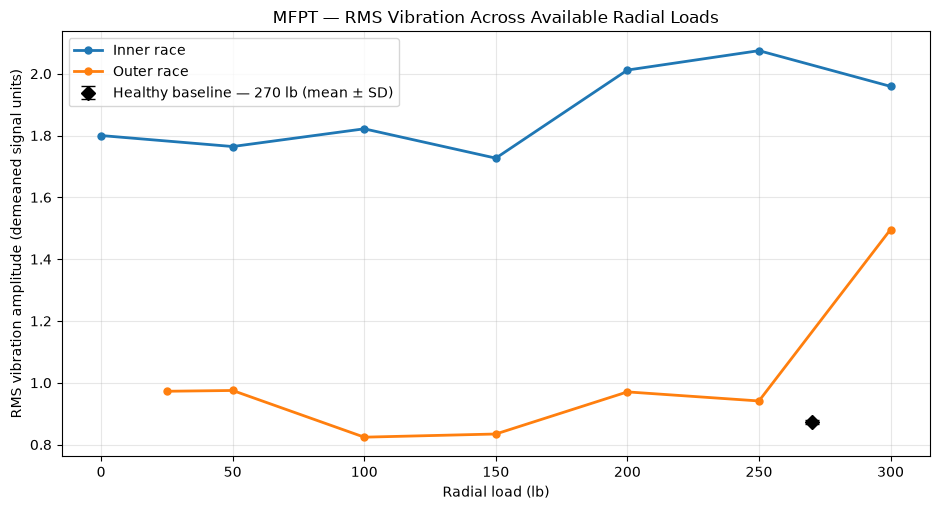

In [24]:
fault_rows = mfpt_summary_df[
    mfpt_summary_df["Fault"].isin(["Inner race", "Outer race"])
    & np.isclose(mfpt_summary_df["Sampling_Rate_Hz"], 48828, atol=1)
].copy()
baseline_rows = mfpt_summary_df[
    (mfpt_summary_df["Fault"] == "Normal")
    & np.isclose(mfpt_summary_df["Load_lb"], 270)
].copy()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for fault in ["Inner race", "Outer race"]:
    subset = fault_rows[fault_rows["Fault"] == fault].sort_values("Load_lb")
    ax.plot(
        subset["Load_lb"], subset["RMS_Demeaned"],
        marker="o", linewidth=2, markersize=5, label=fault
    )

baseline_mean = baseline_rows["RMS_Demeaned"].mean()
baseline_std = baseline_rows["RMS_Demeaned"].std(ddof=1)
ax.errorbar(
    [270], [baseline_mean], yerr=[baseline_std],
    fmt="D", color="black", capsize=5, markersize=7,
    label="Healthy baseline — 270 lb (mean ± SD)"
)
ax.set_xlabel("Radial load (lb)")
ax.set_ylabel("RMS vibration amplitude (demeaned signal units)")
ax.set_title("MFPT — RMS Vibration Across Available Radial Loads")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "Fig_B3_MFPT_RMS_vs_Load.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Export the report figures and supporting tables


In [25]:
# Export recording-level metadata/statistics and theoretical characteristic frequencies.
frequency_table = pd.DataFrame([{
    "Shaft_Rate_Hz": float(shaft_rate),
    "Shaft_RPM": float(mfpt_kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["shaft_rpm"]),
    "BPFO_Hz": float(mfpt_kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["BPFO_Hz"]),
    "BPFI_Hz": float(mfpt_kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["BPFI_Hz"]),
    "BSF_Hz": float(mfpt_kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["BSF_Hz"]),
    "FTF_Hz": float(mfpt_kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["FTF_Hz"]),
} for shaft_rate in sorted(mfpt_summary_df["Shaft_Rate_Hz"].unique())])

mfpt_summary_df.to_csv(TABLE_DIR / "MFPT_Recording_Metadata_and_Statistics.csv", index=False)
frequency_table.to_csv(TABLE_DIR / "MFPT_Kinematic_Frequency_Table.csv", index=False)

print("Saved report figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print(" -", p.name)
print("\nSaved supporting tables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", p.name)

display(frequency_table.round(4))

Saved report figures:
 - Fig_B1_MFPT_Inner_Race_FFT_Loads.png
 - Fig_B2_MFPT_Outer_Race_FFT_Loads.png
 - Fig_B3_MFPT_RMS_vs_Load.png

Saved supporting tables:
 - MFPT_Kinematic_Frequency_Table.csv
 - MFPT_Recording_Metadata_and_Statistics.csv


,Shaft_Rate_Hz,Shaft_RPM,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz
0,25.0,1500.0,81.1245,118.8755,63.864,10.1406


In [26]:
# Bundle only the three report figures and the two supporting CSV tables.
OUTPUT_ZIP = shutil.make_archive(
    "MFPT_Report_Outputs",
    "zip",
    root_dir=OUTPUT_DIR
)
print("Report-output archive:", OUTPUT_ZIP)
print("Included: 3 figures and 2 tables")

Report-output archive: /home/darshan/DLA/run_nb/MFPT_Report_Outputs.zip
Included: 3 figures and 2 tables


## Notes

- The MFPT variable load inner race records cover 0–300 lb in 50 lb steps. The outer race records cover 25–300 lb, with the same 50 lb increments after 25 lb.
- All variable load fault records are 48.828 kHz and 3 s. The three healthy baseline repeats are 97.656 kHz and 6 s at 270 lb. Because sampling rates and record durations differ, the healthy baseline is included as a separate RMS reference only, it is not overlaid on the fault FFT curves.
- RMS describes overall signal amplitude, it is not by itself a fault detector.
- These are my baseline analyses. Resonance filtering, Hilbert envelope demodulation, SES, and adaptive thresholding are done by my other team members.

# Member 2 — Nikunj

#Member 2 - Nikunj

## Data Acquisition and Pre-Processing

This section loads the 12 kHz Drive-End bearing vibration signal — the outer-race 6 o'clock record (7-mil defect, 0 HP / 1797 RPM) selected in Member 1 — and performs time-domain detrending (DC offset subtraction) to ensure a zero-mean input prior to sub-band decomposition.


In [27]:
import os
import warnings
import urllib.request
import numpy as np
import scipy.io as sio
import scipy.signal as signal
import scipy.stats as stats
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'figure.dpi': 120
})

def load_vibration_signal(fault_name="Outer Race (6 o'clock)", rpm=1797, duration_sec=2.0):
    """
    Returns the real 12 kHz Drive-End CWRU record selected in Member 1
    (outer-race 6 o'clock, 7-mil defect, 0 HP / 1797 RPM) and its sampling rate.
    """
    if "records_by_fault" not in globals():
        raise RuntimeError("Run the Member 1 CWRU section first: records_by_fault is undefined.")
    record = records_by_fault[fault_name][rpm]
    fs = float(record["sampling_rate_hz"])
    x_raw = np.asarray(record["signal"], dtype=np.float64)[:int(duration_sec * fs)]
    x_0 = x_raw - np.mean(x_raw)
    return x_0, fs

def cwru_fault_frequency(rpm, key="BPFO_Hz"):
    """Characteristic defect frequency at a given shaft speed (Member 1 kinematics table)."""
    return float(cwru_frequency_table.loc[cwru_frequency_table["RPM"] == rpm, key].iloc[0])

x_0, fs = load_vibration_signal()
print("Sampling Frequency (fs):", fs, "Hz | Signal Length:", len(x_0), "samples | Zero-Mean Check:", round(np.mean(x_0), 12))
print("Record: Outer Race (6 o'clock), 7 mil, 0 HP / 1797 RPM | BPFO =", round(cwru_fault_frequency(1797), 2), "Hz")


Sampling Frequency (fs): 12000.0 Hz | Signal Length: 24000 samples | Zero-Mean Check: -0.0
Record: Outer Race (6 o'clock), 7 mil, 0 HP / 1797 RPM | BPFO = 107.36 Hz


## Sub-Band Filter Bank / Fast Kurtogram Algorithm

Sub-Band Filter Bank and Fast Kurtogram Selection

This section decomposes the Nyquist frequency range [0, fs/2] across multiple dyadic and 1/3-binary levels. For each sub-band, the fourth standardized central moment (Kurtosis) is computed to quantify transient impulsiveness and automatically identify the optimal structural resonance center frequency (fc) and bandwidth (BW).

Optimal Center Frequency (fc): 5181.82 Hz
Optimal Bandwidth (BW): 545.45 Hz
Selected Passband Cutoffs: 4909.09 Hz to 5454.55 Hz
Maximum Sub-Band Kurtosis: 7.81


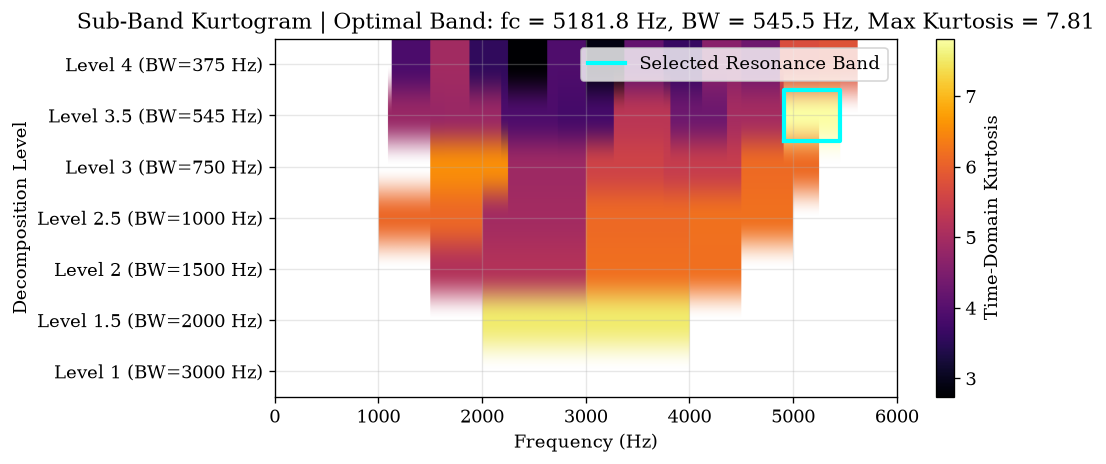

In [28]:
def compute_subband_kurtogram(x_0, fs, levels=[1, 1.5, 2, 2.5, 3, 3.5, 4]):
    nyquist = fs / 2.0
    results = []
    f_min_guard = 1000.0
    f_max_guard = nyquist - 150.0

    for level in levels:
        n_bands = int(round(2 ** level))
        bw = nyquist / n_bands

        for b in range(n_bands):
            f_low = b * bw
            f_high = (b + 1) * bw
            f_c = 0.5 * (f_low + f_high)

            if f_low < f_min_guard or f_high > f_max_guard:
                kurt_val = -np.inf
            else:
                sos_sub = signal.butter(
                    N=4,
                    Wn=[f_low / nyquist, f_high / nyquist],
                    btype='bandpass',
                    output='sos'
                )
                y_sub = signal.sosfiltfilt(sos_sub, x_0)
                kurt_val = stats.kurtosis(y_sub, fisher=False)

            results.append({
                'level': level,
                'n_bands': n_bands,
                'f_low': f_low,
                'f_high': f_high,
                'f_c': f_c,
                'bw': bw,
                'kurtosis': kurt_val
            })

    best_band = max(results, key=lambda d: d['kurtosis'])
    return best_band, results

def plot_kurtogram_map(results, best_band, fs):
    levels = sorted(list(set(r['level'] for r in results)))
    nyquist = fs / 2.0
    grid = np.zeros((len(levels), 1000))
    freqs = np.linspace(0, nyquist, 1000)

    for i, lvl in enumerate(levels):
        lvl_bands = [r for r in results if r['level'] == lvl]
        for b in lvl_bands:
            mask = (freqs >= b['f_low']) & (freqs <= b['f_high'])
            grid[i, mask] = b['kurtosis']

    plt.figure(figsize=(9, 4))
    im = plt.imshow(
        np.ma.masked_invalid(grid), aspect='auto', origin='lower',
        extent=[0, nyquist, 0, len(levels)],
        cmap='inferno'
    )
    plt.colorbar(im, label='Time-Domain Kurtosis')
    plt.yticks(np.arange(len(levels)) + 0.5, [f"Level {l} (BW={int(nyquist/round(2**l))} Hz)" for l in levels])
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Decomposition Level')
    plt.title(
        f"Sub-Band Kurtogram | Optimal Band: fc = {best_band['f_c']:.1f} Hz, "
        f"BW = {best_band['bw']:.1f} Hz, Max Kurtosis = {best_band['kurtosis']:.2f}"
    )

    lvl_idx = levels.index(best_band['level'])
    plt.plot(
        [best_band['f_low'], best_band['f_high'], best_band['f_high'], best_band['f_low'], best_band['f_low']],
        [lvl_idx, lvl_idx, lvl_idx + 1, lvl_idx + 1, lvl_idx],
        color='cyan', linewidth=2.5, label='Selected Resonance Band'
    )
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

best_band, kurt_results = compute_subband_kurtogram(x_0, fs)

print("Optimal Center Frequency (fc):", round(best_band['f_c'], 2), "Hz")
print("Optimal Bandwidth (BW):", round(best_band['bw'], 2), "Hz")
print("Selected Passband Cutoffs:", round(best_band['f_low'], 2), "Hz to", round(best_band['f_high'], 2), "Hz")
print("Maximum Sub-Band Kurtosis:", round(best_band['kurtosis'], 2))

plot_kurtogram_map(kurt_results, best_band, fs)

## Bandpass Filter Design: Kaiser-Windowed FIR vs. Butterworth Cascade SOS IIR

Using the optimal passband [f_low, f_high], this section designs a Linear-Phase Type-I Kaiser-Windowed FIR bandpass filter (N = 128, beta = 8.0) and a 4th-order Butterworth IIR bandpass filter via the Bilinear Transform in Cascade Second-Order Sections (SOS) form. Zero-phase forward-backward filtering (filtfilt and sosfiltfilt) is applied to eliminate phase distortion and group delay dispersion.

In [29]:
def design_and_apply_filters(x_0, fs, f_low, f_high, fir_numtaps=129, kaiser_beta=8.0, iir_order=4, filter_type='both'):
    nyquist = fs / 2.0
    wn = [f_low / nyquist, f_high / nyquist]

    b_fir = signal.firwin(numtaps=fir_numtaps, cutoff=wn, window=('kaiser', kaiser_beta), pass_zero='bandpass')
    a_fir = np.array([1.0])

    sos_iir = signal.butter(N=iir_order, Wn=wn, btype='bandpass', output='sos')
    b_iir, a_iir = signal.sos2tf(sos_iir)

    # Only run the time-domain path that the caller actually needs. The benchmark
    # loop uses the IIR output, so skipping the 129-tap FIR saves a full pass.
    y_bp_fir = signal.filtfilt(b_fir, a_fir, x_0) if filter_type in ('both', 'fir') else None
    y_bp_iir = signal.sosfiltfilt(sos_iir, x_0) if filter_type in ('both', 'iir') else None

    return {
        'b_fir': b_fir,
        'a_fir': a_fir,
        'sos_iir': sos_iir,
        'b_iir': b_iir,
        'a_iir': a_iir,
        'y_bp_fir': y_bp_fir,
        'y_bp_iir': y_bp_iir
    }

filter_data = design_and_apply_filters(
    x_0, fs,
    f_low=best_band['f_low'],
    f_high=best_band['f_high']
)

y_bp = filter_data['y_bp_iir']

print("FIR Filter Length (Taps):", len(filter_data['b_fir']), "(Type-I Linear-Phase)")
print("IIR Cascade SOS Matrix Shape:", filter_data['sos_iir'].shape)
print("Bandpass Filtered Output Signal Shape:", y_bp.shape)

FIR Filter Length (Taps): 129 (Type-I Linear-Phase)
IIR Cascade SOS Matrix Shape: (4, 6)
Bandpass Filtered Output Signal Shape: (24000,)


## Z-Plane Pole-Zero Geometry, Magnitude Response, and Group Delay Analysis(Figure 1)

This section evaluates the pole-zero distribution in the complex z-plane to verify bounded-input bounded-output (BIBO) stability, compares the frequency-domain magnitude and phase responses of the Kaiser FIR and Butterworth SOS IIR designs, and contrasts causal group delay against zero-phase forward-backward filtering.

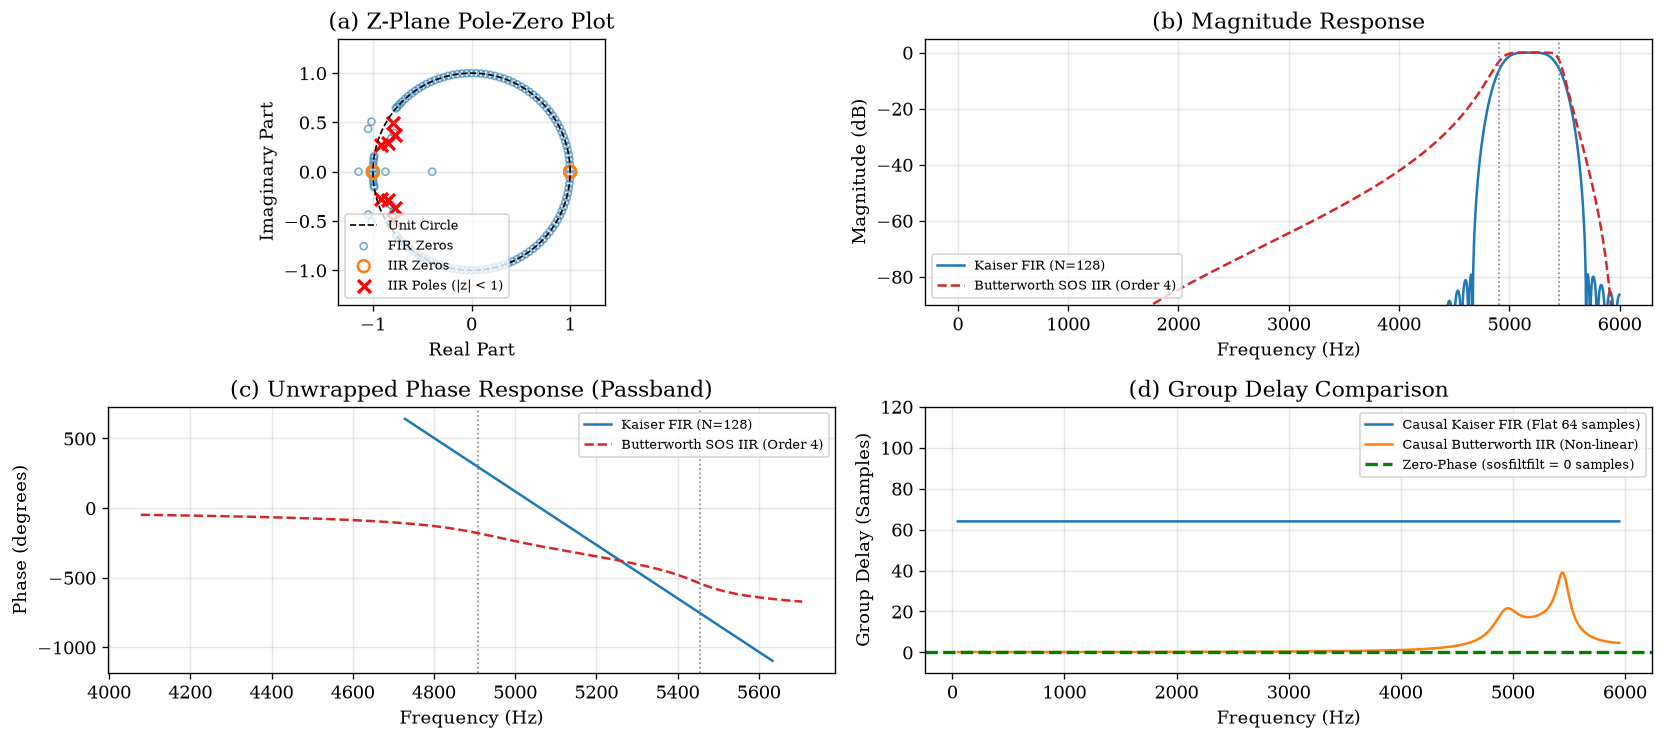

Maximum IIR Pole Radius: 0.9626 (Strictly inside unit circle |z| < 1)


In [30]:
def plot_figure1_filter_comparison(filter_data, best_band, fs):
    b_fir = filter_data['b_fir']
    sos_iir = filter_data['sos_iir']
    b_iir = filter_data['b_iir']
    a_iir = filter_data['a_iir']

    w_fir, h_fir = signal.freqz(b_fir, [1.0], worN=2048, fs=fs)
    w_iir, h_iir = signal.sosfreqz(sos_iir, worN=2048, fs=fs)

    eval_freqs = np.linspace(50.0, (fs / 2.0) - 50.0, 1024)
    w_gd_fir, gd_fir = signal.group_delay((b_fir, [1.0]), w=eval_freqs, fs=fs)
    w_gd_iir, gd_iir = signal.group_delay((b_iir, a_iir), w=eval_freqs, fs=fs)

    z_iir, p_iir, _ = signal.sos2zpk(sos_iir)
    z_fir = np.roots(b_fir)

    fig, axes = plt.subplots(2, 2, figsize=(14, 6.3))

    ax1 = axes[0, 0]
    theta = np.linspace(0, 2 * np.pi, 400)
    ax1.plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.0, label='Unit Circle')
    ax1.scatter(np.real(z_fir), np.imag(z_fir), s=18, facecolors='none', edgecolors='tab:blue', alpha=0.6, label='FIR Zeros')
    ax1.scatter(np.real(z_iir), np.imag(z_iir), s=50, facecolors='none', edgecolors='tab:orange', linewidth=1.5, label='IIR Zeros')
    ax1.scatter(np.real(p_iir), np.imag(p_iir), s=60, marker='x', color='red', linewidth=2.0, label='IIR Poles (|z| < 1)')
    ax1.set_title('(a) Z-Plane Pole-Zero Plot')
    ax1.set_xlabel('Real Part')
    ax1.set_ylabel('Imaginary Part')
    ax1.set_xlim([-1.35, 1.35])
    ax1.set_ylim([-1.35, 1.35])
    ax1.set_aspect('equal')
    ax1.legend(loc='lower left', fontsize=8)

    ax2 = axes[0, 1]
    mag_fir_db = 20 * np.log10(np.maximum(np.abs(h_fir), 1e-6))
    mag_iir_db = 20 * np.log10(np.maximum(np.abs(h_iir), 1e-6))
    ax2.plot(w_fir, mag_fir_db, label='Kaiser FIR (N=128)', color='tab:blue', linewidth=1.5)
    ax2.plot(w_iir, mag_iir_db, label='Butterworth SOS IIR (Order 4)', color='tab:red', linestyle='--', linewidth=1.5)
    ax2.axvline(best_band['f_low'], color='gray', linestyle=':', linewidth=1.0)
    ax2.axvline(best_band['f_high'], color='gray', linestyle=':', linewidth=1.0)
    ax2.set_title('(b) Magnitude Response')
    ax2.set_xlabel('Frequency (Hz)')
    ax2.set_ylabel('Magnitude (dB)')
    ax2.set_ylim([-90, 5])
    ax2.legend(loc='lower left', fontsize=8)

    ax3 = axes[1, 0]
    phase_fir = np.degrees(np.unwrap(np.angle(h_fir)))
    phase_iir = np.degrees(np.unwrap(np.angle(h_iir)))
    # The phase of a near-zero stopband magnitude is dominated by numerical noise
    pass_fir = np.abs(h_fir) >= 1e-2 * np.abs(h_fir).max()
    pass_iir = np.abs(h_iir) >= 1e-2 * np.abs(h_iir).max()
    ax3.plot(w_fir[pass_fir], phase_fir[pass_fir], label='Kaiser FIR (N=128)', color='tab:blue', linewidth=1.5)
    ax3.plot(w_iir[pass_iir], phase_iir[pass_iir], label='Butterworth SOS IIR (Order 4)', color='tab:red', linestyle='--', linewidth=1.5)
    ax3.axvline(best_band['f_low'], color='gray', linestyle=':', linewidth=1.0)
    ax3.axvline(best_band['f_high'], color='gray', linestyle=':', linewidth=1.0)
    ax3.set_title('(c) Unwrapped Phase Response (Passband)')
    ax3.set_xlabel('Frequency (Hz)')
    ax3.set_ylabel('Phase (degrees)')
    ax3.legend(loc='upper right', fontsize=8)

    ax4 = axes[1, 1]
    ax4.plot(w_gd_fir, gd_fir, label='Causal Kaiser FIR (Flat 64 samples)', color='tab:blue', linewidth=1.5)
    ax4.plot(w_gd_iir, np.clip(gd_iir, 0, 150), label='Causal Butterworth IIR (Non-linear)', color='tab:orange', linewidth=1.5)
    ax4.axhline(0, color='green', linestyle='--', linewidth=2.0, label='Zero-Phase (sosfiltfilt = 0 samples)')
    ax4.set_title('(d) Group Delay Comparison')
    ax4.set_xlabel('Frequency (Hz)')
    ax4.set_ylabel('Group Delay (Samples)')
    ax4.set_ylim([-10, 120])
    ax4.legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    plt.savefig('Figure1_Filter_PoleZero_Comparison.png', dpi=300)
    plt.show()
    print("Maximum IIR Pole Radius:", round(np.max(np.abs(p_iir)), 4), "(Strictly inside unit circle |z| < 1)")

plot_figure1_filter_comparison(filter_data, best_band, fs)


## Time-Domain Signal Progression and Resonance Demodulation Pipeline (Figure 2)

This section illustrates a 100 ms time-domain progression comparing the broadband noisy vibration signal x_0[n], the Kurtosis-guided zero-phase bandpass filtered signal y_bp[n], and the corresponding Hilbert envelope |z[n]| isolating periodic fault impacts. It also provides the unified resonance filtering pipeline function.

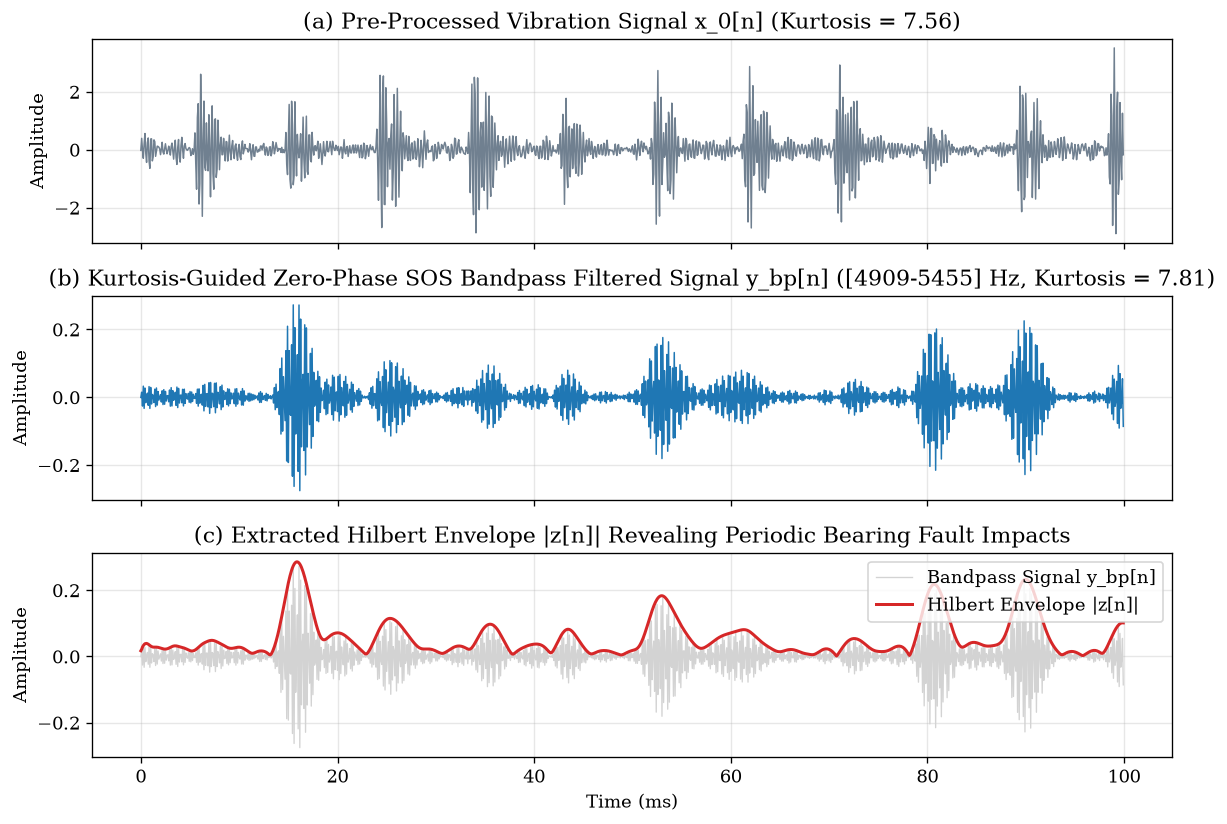

In [31]:
def plot_figure2_time_progression(x_0, y_bp, best_band, fs, duration_sec=0.10):
    n_samples = int(duration_sec * fs)
    t = np.arange(n_samples) / fs * 1000.0

    x_seg = x_0[:n_samples]
    y_seg = y_bp[:n_samples]

    analytic_signal = signal.hilbert(y_bp)
    envelope = np.abs(analytic_signal)[:n_samples]

    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

    axes[0].plot(t, x_seg, color='slategray', linewidth=0.9)
    axes[0].set_title(f"(a) Pre-Processed Vibration Signal x_0[n] (Kurtosis = {stats.kurtosis(x_0, fisher=False):.2f})")
    axes[0].set_ylabel('Amplitude')

    axes[1].plot(t, y_seg, color='tab:blue', linewidth=0.9)
    axes[1].set_title(
        f"(b) Kurtosis-Guided Zero-Phase SOS Bandpass Filtered Signal y_bp[n] "
        f"([{best_band['f_low']:.0f}-{best_band['f_high']:.0f}] Hz, Kurtosis = {stats.kurtosis(y_bp, fisher=False):.2f})"
    )
    axes[1].set_ylabel('Amplitude')

    axes[2].plot(t, y_seg, color='lightgray', linewidth=0.8, label='Bandpass Signal y_bp[n]')
    axes[2].plot(t, envelope, color='tab:red', linewidth=1.8, label='Hilbert Envelope |z[n]|')
    axes[2].set_title('(c) Extracted Hilbert Envelope |z[n]| Revealing Periodic Bearing Fault Impacts')
    axes[2].set_xlabel('Time (ms)')
    axes[2].set_ylabel('Amplitude')
    axes[2].legend(loc='upper right')

    plt.tight_layout()
    plt.savefig('Figure2_Time_Domain_Progression.png', dpi=300)
    plt.show()

plot_figure2_time_progression(x_0, y_bp, best_band, fs)

def kurtosis_guided_bandpass_pipeline(x_0, fs, filter_type='iir'):
    x_zero_mean = x_0 - np.mean(x_0)
    best_band, _ = compute_subband_kurtogram(x_zero_mean, fs)
    f_data = design_and_apply_filters(x_zero_mean, fs, best_band['f_low'], best_band['f_high'], filter_type=filter_type)
    y_bp_out = f_data['y_bp_iir'] if filter_type == 'iir' else f_data['y_bp_fir']
    return y_bp_out, best_band

# Member 3 - Darshan

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# =====================================================================
# 1. CORE MEMBER 3 FUNCTIONS (Importable by Member 4)
# =====================================================================









# =====================================================================
# 2. REAL CWRU RECORDS & FIGURE 3 EXPORT
# =====================================================================


In [33]:
def compute_calibrated_ses(y_bp, fs):
    """
    Computes Analytic Signal via Hilbert Transform, Squared Envelope e[n] = |z[n]|^2,
    Mean removal, Hann Windowing, and Coherent-Gain Calibrated Radix-2 FFT.
    """
    N = len(y_bp)
    z_analytic = hilbert(y_bp)
    sq_env = np.abs(z_analytic) ** 2
    sq_env_zero_mean = sq_env - np.mean(sq_env)

    window = np.hanning(N)
    coherent_gain = np.mean(window)  # 0.5 for Hann window

    N_fft = int(2 ** np.ceil(np.log2(N)))
    fft_vals = np.fft.rfft(sq_env_zero_mean * window, n=N_fft)
    # Coherent-gain calibration removes the Hann loss; the factor of two then
    # restores the positive half of the two-sided spectrum. DC (k = 0) and the
    # Nyquist bin (k = N_FFT/2) have no negative-frequency twin and stay unscaled.
    ses_mag = np.abs(fft_vals) / (N * coherent_gain)
    if N_fft % 2 == 0 and ses_mag.size > 2:
        ses_mag[1:-1] *= 2.0
    freqs = np.fft.rfftfreq(N_fft, d=1.0 / fs)

    return freqs, ses_mag, sq_env

In [34]:
def compute_spectral_thresholds(ses_mag, n_guard=4, n_ref=25,
                                alpha_cfar=3.5, gamma_mad=7.0, static_val=0.0035):
    """
    Computes Static, CA-CFAR, and Proposed Median-MAD thresholds across SES[k].
    """
    K = len(ses_mag)
    thresh_static = np.full(K, static_val)
    thresh_cacfar = np.zeros(K)
    thresh_medmad = np.zeros(K)

    for k in range(K):
        l_start = max(0, k - n_guard - n_ref)
        l_end   = max(0, k - n_guard)
        r_start = min(K, k + n_guard + 1)
        r_end   = min(K, k + n_guard + 1 + n_ref)

        ref_cells = np.concatenate([ses_mag[l_start:l_end], ses_mag[r_start:r_end]])
        if len(ref_cells) == 0:
            continue

        # CA-CFAR (Moving Average)
        thresh_cacfar[k] = alpha_cfar * np.mean(ref_cells)

        # Proposed Median-MAD (Order-Statistic Robust CFAR)
        med = np.median(ref_cells)
        mad = np.median(np.abs(ref_cells - med))
        thresh_medmad[k] = med + gamma_mad * (1.4826 * mad)

    return thresh_static, thresh_cacfar, thresh_medmad

In [35]:
def evaluate_detector(freqs, ses_mag, threshold, f_fault, n_harmonics=3, slip_tol=0.015):
    """
    Evaluates Slip-Tolerant Harmonic Detection (1x, 2x, 3x f_fault) and False Alarms.

    Returns the per-harmonic detection list, the false-alarm bin count and the
    false-alarm rate as a percentage of the eligible (non-fault) bins.
    """
    detected_list = []
    fault_bin_mask = np.zeros(len(freqs), dtype=bool)

    # Mask the fault-harmonic bands so their peaks are not counted as false alarms
    for h in range(1, n_harmonics + 1):
        f_target = h * f_fault
        f_min, f_max = f_target * (1.0 - slip_tol), f_target * (1.0 + slip_tol)
        idx_band = np.where((freqs >= f_min) & (freqs <= f_max))[0]
        fault_bin_mask[idx_band] = True

        if len(idx_band) > 0:
            pk_idx = idx_band[np.argmax(ses_mag[idx_band])]
            is_det = ses_mag[pk_idx] > threshold[pk_idx]
            detected_list.append((h, freqs[pk_idx], ses_mag[pk_idx], threshold[pk_idx], is_det))

    # Count false alarm spikes outside fault harmonic bands (above 15 Hz)
    non_fault_bins = (~fault_bin_mask) & (freqs > 15.0)
    false_alarm_bins = np.sum(ses_mag[non_fault_bins] > threshold[non_fault_bins])
    n_eligible = int(np.count_nonzero(non_fault_bins))
    false_alarm_pct = 100.0 * false_alarm_bins / n_eligible if n_eligible else 0.0

    return detected_list, int(false_alarm_bins), float(false_alarm_pct)

In [36]:
# =====================================================================
# 2. REAL CWRU RECORDS & FIGURE 3 EXPORT
# =====================================================================
def load_fault_record(fault_name, rpm, duration_sec=2.0):
    """Mean-removed Member 1 CWRU record and its sampling rate for one motor load."""
    if "records_by_fault" not in globals():
        raise RuntimeError("Run the Member 1 CWRU section first: records_by_fault is undefined.")
    record = records_by_fault[fault_name][rpm]
    fs = float(record["sampling_rate_hz"])
    x_raw = np.asarray(record["signal"], dtype=np.float64)[:int(duration_sec * fs)]
    return x_raw - np.mean(x_raw), fs

Calibrated static threshold T_static = 0.00228 (0 HP Median-MAD levels: [0.00228, 0.00084, 0.00032])

Motor Load      | Detector       | Harmonics Detected (of 3)  | FAR (%)


0 HP - 1797 RPM | Static         | 2/3 Harmonics              |   1.2%
0 HP - 1797 RPM | CA-CFAR        | 3/3 Harmonics              |   4.8%
0 HP - 1797 RPM | Median-MAD     | 3/3 Harmonics              |   3.7%
------------------------------------------------------------------------------


1 HP - 1772 RPM | Static         | 0/3 Harmonics              |   0.0%
1 HP - 1772 RPM | CA-CFAR        | 3/3 Harmonics              |   8.6%
1 HP - 1772 RPM | Median-MAD     | 3/3 Harmonics              |   7.4%
------------------------------------------------------------------------------


2 HP - 1750 RPM | Static         | 3/3 Harmonics              |   1.9%
2 HP - 1750 RPM | CA-CFAR        | 3/3 Harmonics              |   4.5%
2 HP - 1750 RPM | Median-MAD     | 3/3 Harmonics              |   3.6%
------------------------------------------------------------------------------


3 HP - 1730 RPM | Static         | 3/3 Harmonics              |   2.0%
3 HP - 1730 RPM | CA-CFAR        | 3/3 Harmonics              |   6.7%
3 HP - 1730 RPM | Median-MAD     | 3/3 Harmonics              |   5.0%
------------------------------------------------------------------------------



[SUCCESS] Saved high-resolution plot: Fig3_MultiLoad_SES_Thresholding.png



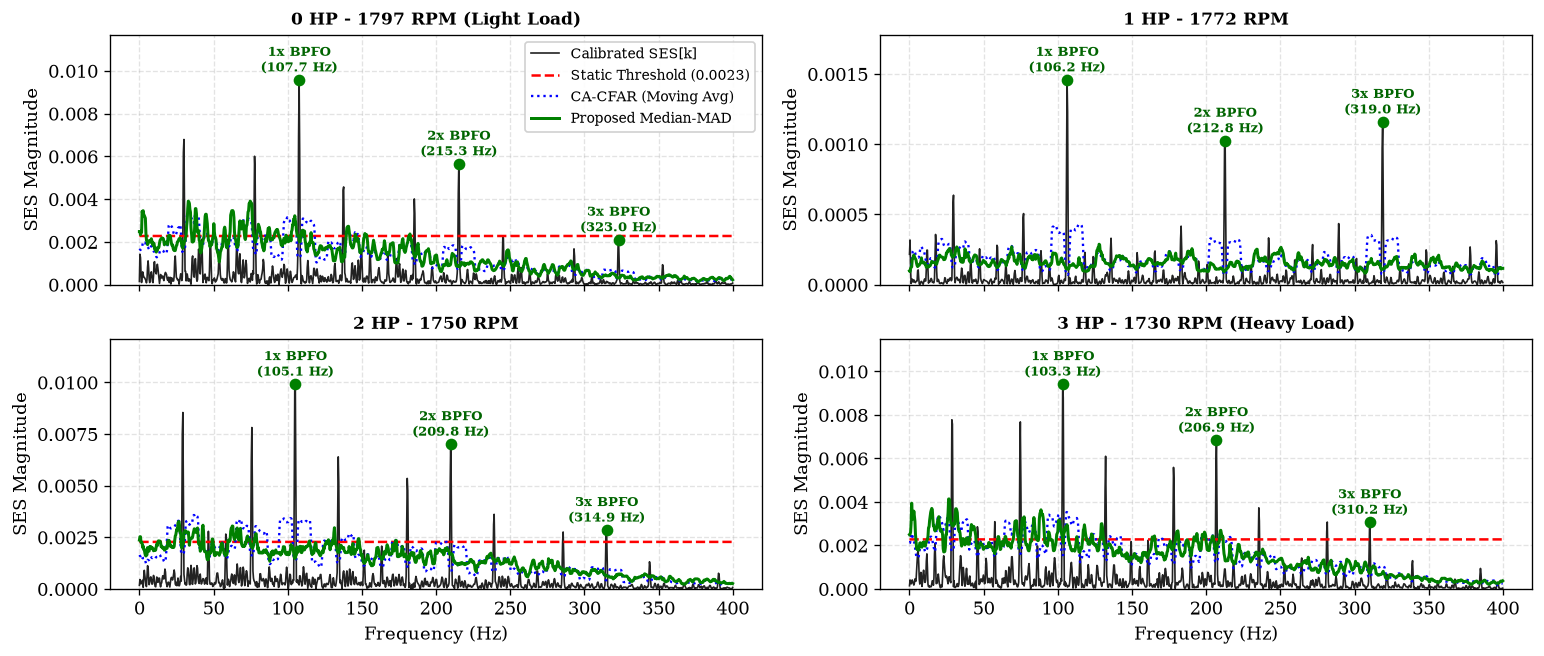

In [37]:
if __name__ == "__main__":
    fault_name = "Outer Race (6 o'clock)"

    # Calibrate the fixed threshold on the 0 HP reference segment only: take
    # the largest Median-MAD threshold found in its three BPFO harmonic
    # windows, i.e. the level a "set it at no load" calibration would choose.
    x_ref, fs_ref = load_fault_record(fault_name, 1797)
    y_bp_ref, _ = kurtosis_guided_bandpass_pipeline(x_ref, fs_ref, filter_type='iir')
    f_ref, ses_ref, _ = compute_calibrated_ses(y_bp_ref, fs_ref)
    f_bpfo_ref = cwru_fault_frequency(1797)

    ref_band = f_ref <= 650.0
    f_ref_band, ses_ref_band = f_ref[ref_band], ses_ref[ref_band]
    _, _, t_mad_ref = compute_spectral_thresholds(ses_ref_band)

    harmonic_mad = []
    for h in (1, 2, 3):
        lo, hi = h * f_bpfo_ref * 0.985, h * f_bpfo_ref * 1.015
        idx = np.where((f_ref_band >= lo) & (f_ref_band <= hi))[0]
        if idx.size:
            pk = idx[np.argmax(ses_ref_band[idx])]
            harmonic_mad.append(float(t_mad_ref[pk]))
    STATIC_THRESHOLD = max(harmonic_mad)
    print(f"Calibrated static threshold T_static = {STATIC_THRESHOLD:.5f} "
          f"(0 HP Median-MAD levels: {[round(v, 5) for v in harmonic_mad]})")

    # 0-3 HP CWRU records loaded by Member 1; BPFO per shaft speed from its kinematics table.
    load_configs = [
        ("0 HP - 1797 RPM (Light Load)", 1797),
        ("1 HP - 1772 RPM",               1772),
        ("2 HP - 1750 RPM",               1750),
        ("3 HP - 1730 RPM (Heavy Load)",  1730),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(13, 5.6), sharex=True)
    axes = axes.flatten()

    print("\n" + "="*78)
    print(f"{'Motor Load':<15} | {'Detector':<14} | {'Harmonics Detected (of 3)':<26} | {'FAR (%)'}")
    print("="*78)

    for idx, (title, rpm) in enumerate(load_configs):
        ax = axes[idx]
        x_load, fs_load = load_fault_record(fault_name, rpm)
        y_bp_load, _ = kurtosis_guided_bandpass_pipeline(x_load, fs_load, filter_type='iir')
        f_bpfo = cwru_fault_frequency(rpm)

        freqs, ses_mag, _ = compute_calibrated_ses(y_bp_load, fs_load)

        # Estimate the three thresholds on the SES up to 650 Hz first, so the
        # CFAR windows keep their right-hand reference cells, then crop the
        # spectrum and all three thresholds to the 0-400 Hz plotting band.
        thr_mask = freqs <= 650.0
        f_thr, ses_thr = freqs[thr_mask], ses_mag[thr_mask]
        t_stat_full, t_cfar_full, t_mad_full = compute_spectral_thresholds(
            ses_thr, static_val=STATIC_THRESHOLD)

        mask = f_thr <= 400.0
        f_plot, ses_plot = f_thr[mask], ses_thr[mask]
        t_stat, t_cfar, t_mad = t_stat_full[mask], t_cfar_full[mask], t_mad_full[mask]

        # Evaluate all 3 methods for terminal printout
        for name, th in [("Static", t_stat), ("CA-CFAR", t_cfar), ("Median-MAD", t_mad)]:
            dets, fa_bins, fa_pct = evaluate_detector(f_plot, ses_plot, th, f_bpfo)
            n_det = sum(1 for d in dets if d[4])
            print(f"{title[:15]:<15} | {name:<14} | {f'{n_det}/3 Harmonics':<26} | {fa_pct:5.1f}%")
        print("-" * 78)

        # Plot Figure 3
        harmonics_mad, _, _ = evaluate_detector(f_plot, ses_plot, t_mad, f_bpfo)
        ax.plot(f_plot, ses_plot, color='#222222', lw=1.0, label='Calibrated SES[k]')
        ax.plot(f_plot, t_stat, 'r--', lw=1.5, label=f'Static Threshold ({STATIC_THRESHOLD:.4f})')
        ax.plot(f_plot, t_cfar, 'b:', lw=1.4, label='CA-CFAR (Moving Avg)')
        ax.plot(f_plot, t_mad, 'g-', lw=1.8, label='Proposed Median-MAD')

        for h, pf, pv, tv, det in harmonics_mad:
            if det:
                ax.plot(pf, pv, 'go', markersize=6)
                ax.annotate(f"{h}x BPFO\n({pf:.1f} Hz)", (pf, pv), textcoords="offset points",
                            xytext=(0, 5), ha='center', fontsize=7.5, color='darkgreen', weight='bold')

        peak_scale = max(float(np.max(ses_plot)), float(np.max(t_mad)), 1e-6)
        ax.set_ylim(0.0, 1.22 * peak_scale)
        ax.set_title(title, fontsize=10, weight='bold')
        ax.set_ylabel("SES Magnitude")
        ax.grid(True, linestyle='--', alpha=0.35)
        if idx >= 2:
            ax.set_xlabel("Frequency (Hz)")
        if idx == 0:
            ax.legend(loc='upper right', fontsize=8.5, framealpha=0.9)

    plt.tight_layout()
    plt.savefig("Fig3_MultiLoad_SES_Thresholding.png", dpi=300, bbox_inches='tight')
    print("\n[SUCCESS] Saved high-resolution plot: Fig3_MultiLoad_SES_Thresholding.png\n")
    plt.show()


In [38]:
def run_member3_pipeline(y_bp, fs, f_fault, max_freq=400.0, static_val=0.0035):
    freqs, ses_mag, sq_env = compute_calibrated_ses(y_bp, fs)
    # Thresholds are estimated on the SES up to 650 Hz and only then cropped,
    # so the reference windows at the upper edge keep their right-hand cells.
    thr_mask = freqs <= 650.0
    f_thr, ses_thr = freqs[thr_mask], ses_mag[thr_mask]
    t_stat_full, t_cfar_full, t_mad_full = compute_spectral_thresholds(ses_thr, static_val=static_val)
    mask = f_thr <= max_freq
    f_plot, ses_plot = f_thr[mask], ses_thr[mask]
    t_stat, t_cfar, t_mad = t_stat_full[mask], t_cfar_full[mask], t_mad_full[mask]
    dets_mad, fa_bins, fa_pct = evaluate_detector(f_plot, ses_plot, t_mad, f_fault)
    return f_plot, ses_plot, t_stat, t_cfar, t_mad, dets_mad, fa_bins, fa_pct


# Member 4


CWRU: inner / ball / outer faults at 7, 14 and 21 mil across 0-3 HP
Dataset  | Condition                  | Detector              |       TDR (%) |       FAR (%) |       dSNR (dB) |    Latency (ms)
------------------------------------------------------------------------------------------------------------
CWRU     | Inner race 7 mil           | Static                |  65.0±15.7 |   9.1± 6.4 |  +5.13±0.80 |   372.1± 31.1
CWRU     | Inner race 7 mil           | CA-CFAR               | 100.0± 0.0 |   8.5± 0.9 |  +5.13±0.80 |   372.1± 31.1
CWRU     | Inner race 7 mil           | Median-MAD (Proposed) | 100.0± 0.0 |   7.4± 1.0 |  +5.13±0.80 |   372.1± 31.1
CWRU     | Inner race 14 mil          | Static                |  95.0±11.2 |  36.1±13.7 |  -2.54±1.92 |   354.7± 37.9
CWRU     | Inner race 14 mil          | CA-CFAR               |  98.3± 3.7 |   9.1± 1.3 |  -2.54±1.92 |   354.7± 37.9
CWRU     | Inner race 14 mil          | Median-MAD (Proposed) |  93.3± 8.3 |   9.7± 2.0 |  -2.54±1.92 

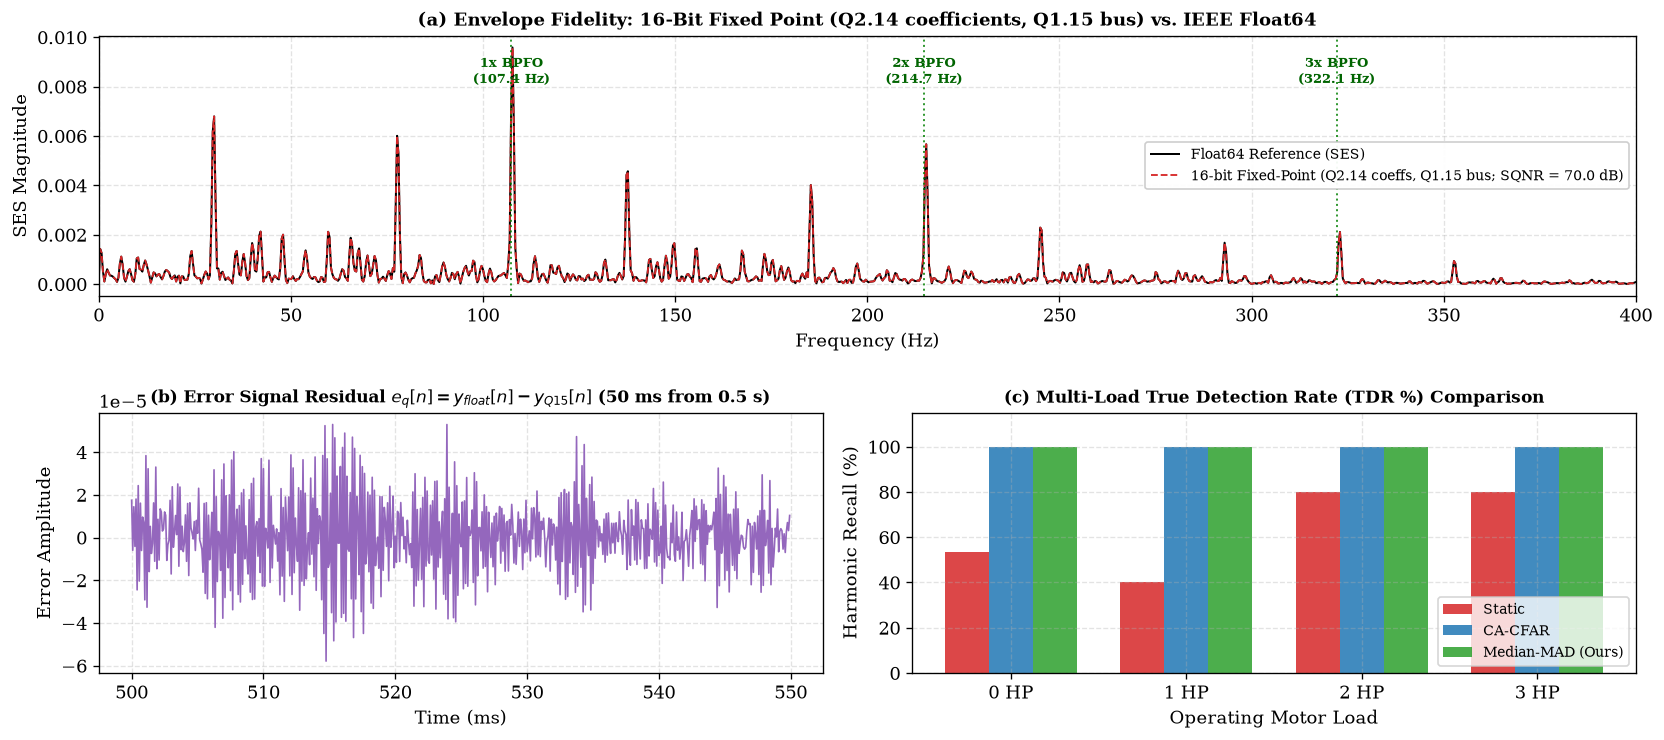

[SUCCESS] Exported Figure 4: Figure4_Benchmarking_and_FWL_Analysis.png
Fixed-point SQNR: 70.05 dB across the passband.
Quantized pole radius: r_max_q = 0.962619 (stable: True).


In [39]:
# =====================================================================
# Member 4 - Multi-Load Benchmarking, Quantitative Metrics & FWL Lead
# =====================================================================
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.signal as signal
import scipy.stats as stats
import matplotlib.pyplot as plt

# =====================================================================
# 1. METRICS & FINITE-WORD-LENGTH (FWL) UTILITIES
# =====================================================================

def calculate_spectral_snr(freqs, spectrum, f_fault, n_harmonics=3, slip_tol=0.015):
    """
    Spectral defect-to-noise ratio, Eq. (35):

        (1/M) * sum_m max_{k in B_m} |S[k]|^2  /  mean_{k in K_noise} |S[k]|^2

    The magnitude spectrum is that of a Hann-windowed, zero-padded one-sided
    FFT, so the same estimator serves the raw record and the SES.
    """
    harmonic_power = 0.0
    fault_mask = np.zeros(len(freqs), dtype=bool)

    for h in range(1, n_harmonics + 1):
        f_target = h * f_fault
        f_min, f_max = f_target * (1.0 - slip_tol), f_target * (1.0 + slip_tol)
        idx_band = np.where((freqs >= f_min) & (freqs <= f_max))[0]
        if len(idx_band) > 0:
            fault_mask[idx_band] = True
            harmonic_power += np.max(spectrum[idx_band] ** 2)

    harmonic_power /= float(n_harmonics)

    noise_mask = (~fault_mask) & (freqs >= 10.0)
    noise_power = float(np.mean(spectrum[noise_mask] ** 2)) if np.sum(noise_mask) > 0 else 1e-12

    snr_db = 10.0 * np.log10(max(harmonic_power, 1e-12) / max(noise_power, 1e-12))
    return snr_db

def quantize_to_q15(x):
    """Q1.15 rounding to [-1, 1 - 2^-15] with symmetric saturation."""
    scale = 2**15
    x_scaled = np.clip(x, -1.0, 1.0 - (1.0 / scale))
    return np.round(x_scaled * scale) / scale


def quantize_to_q214(x):
    """Q2.14 rounding to [-2, 2 - 2^-14]; covers every biquad coefficient here."""
    scale = 2**14
    x_scaled = np.clip(x, -2.0, 2.0 - (1.0 / scale))
    return np.round(x_scaled * scale) / scale


def _sosfilt_q15(sos_q, x, stage_scales):
    """Causal SOS cascade with the output of every section rounded to Q1.15."""
    y = np.asarray(x, dtype=np.float64).copy()
    for sec in range(sos_q.shape[0]):
        b0, b1, b2, _, a1, a2 = sos_q[sec, :6]
        out = np.empty_like(y)
        z1 = 0.0
        z2 = 0.0
        for n in range(y.size):
            v = y[n] - a1 * z1 - a2 * z2
            out[n] = b0 * v + b1 * z1 + b2 * z2
            z2, z1 = z1, v
        y = quantize_to_q15(stage_scales[sec] * out)
    return y


def simulate_fixed_point_sos(sos_float, x_input, q_bits=16, fs=None, f_center=None):
    """
    Genuine 16-bit fixed-point SOS simulation matching Eq. (14):

      H(z) = G * prod_k H_k(z),   b0_k normalized to 1 (0.5 where b1_k = +2).

    Each biquad numerator is divided by its own b0_k; the two sections whose
    b1/b0 equals +2 are rescaled by 1/2 because +2 lies outside the Q2.14
    range [-2, 2), and the 1/2 is absorbed into the overall gain G.  The
    numerator and denominator coefficients are rounded to Q2.14, while the
    input, the section outputs and the bus between sections are rounded to
    Q1.15.  A power-of-two scale after each section keeps that Q1.15 bus inside
    [-1, 1); the total gain is restored at the output.  When fs and f_center
    are supplied, a gain trim evaluated on the realized cascade removes the
    residual passband-gain offset left by the coefficient rounding.
    """
    norm_factor = np.max(np.abs(x_input)) * 1.001
    x_norm = x_input / norm_factor
    x_q = quantize_to_q15(x_norm)

    G = float(np.prod(sos_float[:, 0]))
    sos_n = np.asarray(sos_float, dtype=np.float64).copy()
    sos_n[:, :3] = sos_n[:, :3] / sos_n[:, 0:1]

    section_scales = np.ones(sos_n.shape[0], dtype=np.float64)
    for sec in range(sos_n.shape[0]):
        if sos_n[sec, 1] >= 2.0 - 1e-9:          # b1 = +2 is not in Q2.14
            sos_n[sec, :3] *= 0.5
            section_scales[sec] = 0.5

    sos_q = np.empty_like(sos_n)
    sos_q[:, :3] = quantize_to_q214(sos_n[:, :3])
    sos_q[:, 3] = 1.0
    sos_q[:, 4:6] = quantize_to_q214(sos_n[:, 4:6])

    r_max_q = max(float(np.max(np.abs(np.roots([1.0, a1, a2]))))
                  for a1, a2 in sos_q[:, 4:6])

    G_eff = G / float(np.prod(section_scales))

    trim = 1.0
    if fs is not None and f_center is not None:
        w_c = 2.0 * np.pi * float(f_center) / float(fs)
        _, h_ideal = signal.sosfreqz(sos_float, worN=[w_c])
        _, h_q = signal.sosfreqz(sos_q, worN=[w_c])
        trim = (np.abs(h_ideal[0]) / np.abs(G_eff * h_q[0])) ** 2

    def choose_stage_scales(signal_block):
        out_scales = []
        probe = np.asarray(signal_block, dtype=np.float64).copy()
        for sec in range(sos_q.shape[0]):
            probe = signal.sosfilt(sos_q[sec:sec + 1], probe)
            peak = float(np.max(np.abs(probe)))
            scale = 2.0 ** (-np.ceil(np.log2(max(peak, 1e-12) / 0.999)))
            out_scales.append(scale)
            probe = probe * scale
        return np.asarray(out_scales, dtype=np.float64)

    padlen = int(0.05 * fs) if fs is not None else 500
    x_pad = np.pad(x_q, padlen, mode='edge')

    fwd_scales = choose_stage_scales(x_pad)
    y_fwd = _sosfilt_q15(sos_q, x_pad, fwd_scales)

    rev_scales = choose_stage_scales(y_fwd[::-1])
    y_rev = _sosfilt_q15(sos_q, y_fwd[::-1], rev_scales)[::-1]
    y_q_norm = y_rev[padlen:-padlen]

    output_gain = (G_eff ** 2) / float(np.prod(fwd_scales) * np.prod(rev_scales))
    y_q = y_q_norm * output_gain * trim * norm_factor
    return y_q, r_max_q


# =====================================================================
# 2. BATCH EXPERIMENTS ACROSS FAULTS, DEFECT SIZES AND LOADS
# =====================================================================

LOAD_LABELS = {1797: "0 HP", 1772: "1 HP", 1750: "2 HP", 1730: "3 HP"}
DETECTORS = ["Static", "CA-CFAR", "Median-MAD (Proposed)"]


def cwru_records(sizes=(7, 14, 21)):
    """
    Every 12 kHz Drive-End CWRU record in the archive: inner-race, ball and
    outer-race faults at 7, 14 and 21 mil for the four motor loads.
    """
    fault_specs = [
        ("Inner race", "IR", "BPFI_Hz"),
        ("Ball", "B", "BSF_Hz"),
        ("Outer race (6 o'clock)", "OR@6", "BPFO_Hz"),
    ]
    records = []
    for fault_label, code, freq_key in fault_specs:
        for size in sizes:
            for rpm, load_label in LOAD_LABELS.items():
                matches = list(DATA_ROOT.rglob(f"{rpm}_{code}_{size}_DE12.npz"))
                if len(matches) != 1:
                    continue
                records.append({
                    "dataset": "CWRU",
                    "condition": f"{fault_label} {size} mil",
                    "load": load_label,
                    "signal": load_cwru_de12(matches[0]),
                    "fs": SAMPLING_RATE_HZ,
                    "f_fault": cwru_fault_frequency(rpm, freq_key),
                })
    return records


def mfpt_records_for_benchmark():
    """Variable-load MFPT inner/outer race records; empty if the MFPT block was not run."""
    if "mfpt_records" not in globals():
        return []
    records = []
    for name, rec in mfpt_records.items():
        fault = rec.metadata["fault"]
        if fault == "Normal":
            continue
        freqs = mfpt_kinematic_fault_frequencies(rec.metadata["shaft_rate_hz"])
        key = "BPFI_Hz" if fault == "Inner race" else "BPFO_Hz"
        records.append({
            "dataset": "MFPT",
            "condition": fault,
            "load": f"{rec.metadata['load_lbs']:g} lb",
            "signal": rec.signal,
            "fs": rec.sampling_rate,
            "f_fault": freqs[key],
        })
    return records


def cwru_normal_records():
    """Healthy CWRU Drive-End records (normal bearing) at the four load steps."""
    records = []
    for rpm, load_label in LOAD_LABELS.items():
        # Normal records carry no rate suffix; the archive stores them at 12 kHz.
        matches = [p for p in DATA_ROOT.rglob("*.npz")
                   if p.name.startswith(f"{rpm}_Normal")]
        if len(matches) != 1:
            continue
        records.append({
            "dataset": "CWRU (healthy)",
            "condition": "Healthy",
            "load": load_label,
            "signal": load_cwru_de12(matches[0]),
            "fs": SAMPLING_RATE_HZ,
            "f_fault": cwru_fault_frequency(rpm, "BPFO_Hz"),
        })
    return records


def mfpt_normal_records():
    """MFPT baseline recordings; empty if the MFPT block was not run."""
    if "mfpt_records" not in globals():
        return []
    records = []
    for name, rec in mfpt_records.items():
        if rec.metadata["fault"] != "Normal":
            continue
        freqs = mfpt_kinematic_fault_frequencies(rec.metadata["shaft_rate_hz"])
        records.append({
            "dataset": "MFPT (healthy)",
            "condition": "Healthy",
            "load": f"{rec.metadata['load_lbs']:g} lb",
            "signal": rec.signal,
            "fs": rec.sampling_rate,
            "f_fault": freqs["BPFO_Hz"],
        })
    return records


def evaluate_records(records, n_segments=5, segment_sec=2.0, static_val=None):
    """
    Runs the Member 2 + Member 3 chain on every record, segment by segment.

    Returns per-record means and standard deviations (one row per detector) and
    the per-segment rows used to build those statistics.
    """
    if static_val is None:
        static_val = STATIC_THRESHOLD

    rows = []
    segment_rows = []

    for rec in records:
        x_full = np.asarray(rec["signal"], dtype=np.float64)
        fs_rec = float(rec["fs"])
        seg_len = int(segment_sec * fs_rec)
        n_seg = min(n_segments, len(x_full) // seg_len) if seg_len > 0 else 0
        if n_seg < 1:
            seg_len = len(x_full)
            n_seg = 1
        f_fault = float(rec["f_fault"])
        # 400 Hz covers 3x BPFO (322 Hz) but clips the inner-race 3rd harmonic
        # (486.6 Hz); open the band to 3.2 f_fault so every target stays inside.
        max_eval_freq = max(400.0, 3.2 * f_fault)
        metrics = {d: {"tdr": [], "far": [], "snr_raw": [], "snr_ses": [],
                       "delta_snr": [], "latency": []} for d in DETECTORS}

        for seg in range(n_seg):
            # 0. Real record segment
            x_seg = x_full[seg * seg_len:(seg + 1) * seg_len]
            x_0 = x_seg - np.mean(x_seg)

            # Raw baseline SNR: the same zero-padded Hann-windowed one-sided
            # amplitude spectrum used for the SES, cropped to the evaluation band.
            nfft_raw = int(2 ** np.ceil(np.log2(len(x_0))))
            f_raw, mag_raw = single_sided_amplitude_spectrum(
                x_0, fs_rec, window="hann", nfft=nfft_raw)
            raw_mask = f_raw <= max_eval_freq
            snr_raw = calculate_spectral_snr(f_raw[raw_mask], mag_raw[raw_mask], f_fault)

            # 1. Member 2 Kurtogram-Guided Bandpass Pipeline
            t_start = time.perf_counter()
            y_bp, _ = kurtosis_guided_bandpass_pipeline(x_0, fs_rec, filter_type='iir')

            # 2. Member 3 Calibrated SES and Detection
            freqs, ses_mag, _ = compute_calibrated_ses(y_bp, fs_rec)

            # Thresholds are estimated on the SES up to 650 Hz, which leaves
            # every right-hand reference cell in place, and only then cropped
            # to the evaluation band. Cropping before thresholding would
            # truncate the CFAR windows at the upper edge.
            thr_mask = freqs <= 650.0
            f_thr, ses_thr = freqs[thr_mask], ses_mag[thr_mask]
            t_stat_full, t_cfar_full, t_mad_full = compute_spectral_thresholds(
                ses_thr, static_val=static_val)
            mask = f_thr <= max_eval_freq
            f_eval, ses_eval = f_thr[mask], ses_thr[mask]
            snr_ses = calculate_spectral_snr(f_eval, ses_eval, f_fault)
            delta_snr = snr_ses - snr_raw

            thresholds = {"Static": t_stat_full[mask],
                          "CA-CFAR": t_cfar_full[mask],
                          "Median-MAD (Proposed)": t_mad_full[mask]}

            elapsed_ms = (time.perf_counter() - t_start) * 1000.0

            for d_name in DETECTORS:
                dets, fa_bins, fa_pct = evaluate_detector(f_eval, ses_eval, thresholds[d_name], f_fault)
                tdr_seg = sum(1 for d in dets if d[4]) / 3.0 * 100.0
                metrics[d_name]["tdr"].append(tdr_seg)
                metrics[d_name]["far"].append(fa_pct)
                metrics[d_name]["snr_raw"].append(snr_raw)
                metrics[d_name]["snr_ses"].append(snr_ses)
                metrics[d_name]["delta_snr"].append(delta_snr)
                metrics[d_name]["latency"].append(elapsed_ms)
                segment_rows.append({
                    "dataset": rec["dataset"],
                    "condition": rec["condition"],
                    "load": rec["load"],
                    "detector": d_name,
                    "segment": seg,
                    "tdr": tdr_seg,
                    "far_pct": fa_pct,
                    "snr_raw": snr_raw,
                    "snr_ses": snr_ses,
                    "delta_snr": delta_snr,
                    "latency_ms": elapsed_ms,
                })

        for d_name in DETECTORS:
            def mean_std(key):
                values = np.asarray(metrics[d_name][key], dtype=float)
                sd = float(values.std(ddof=1)) if values.size > 1 else 0.0
                return float(values.mean()), sd

            tdr_mean, tdr_sd = mean_std("tdr")
            far_mean, far_sd = mean_std("far")
            snr_raw_mean, _ = mean_std("snr_raw")
            snr_ses_mean, _ = mean_std("snr_ses")
            dsnr_mean, dsnr_sd = mean_std("delta_snr")
            lat_mean, lat_sd = mean_std("latency")

            rows.append({
                "dataset": rec["dataset"],
                "condition": rec["condition"],
                "load": rec["load"],
                "detector": d_name,
                "segments": n_seg,
                "tdr": tdr_mean,
                "tdr_std": tdr_sd,
                "far_pct": far_mean,
                "far_std": far_sd,
                "snr_raw": snr_raw_mean,
                "snr_ses": snr_ses_mean,
                "delta_snr": dsnr_mean,
                "delta_snr_std": dsnr_sd,
                "latency_ms": lat_mean,
                "latency_std": lat_sd,
            })

    return rows, segment_rows


def summarise(rows, title):
    """Print mean and spread per (dataset, condition, detector), averaged over loads."""
    if not rows:
        print(f"\n{title}: no records available.")
        return None
    frame = pd.DataFrame(rows)
    summary = (frame.groupby(["dataset", "condition", "detector"], sort=False)
               .agg(TDR_pct=("tdr", "mean"), TDR_sd=("tdr_std", "mean"),
                    FAR_pct=("far_pct", "mean"), FAR_sd=("far_std", "mean"),
                    SNR_gain_dB=("delta_snr", "mean"), SNR_gain_sd=("delta_snr_std", "mean"),
                    Latency_ms=("latency_ms", "mean"), Latency_sd=("latency_std", "mean"),
                    Loads=("load", "nunique"))
               .reset_index())
    print("\n" + "=" * 108)
    print(title)
    print("=" * 108)
    print(f"{'Dataset':<8} | {'Condition':<26} | {'Detector':<21} | {'TDR (%)':>13} | {'FAR (%)':>13} | {'dSNR (dB)':>15} | {'Latency (ms)':>15}")
    print("-" * 108)
    for _, row in summary.iterrows():
        print(f"{row['dataset']:<8} | {row['condition']:<26} | {row['detector']:<21} | "
              f"{row['TDR_pct']:5.1f}±{row['TDR_sd']:4.1f} | {row['FAR_pct']:5.1f}±{row['FAR_sd']:4.1f} | "
              f"{row['SNR_gain_dB']:+6.2f}±{row['SNR_gain_sd']:4.2f} | "
              f"{row['Latency_ms']:7.1f}±{row['Latency_sd']:5.1f}")
    print("=" * 108)
    return summary


# =====================================================================
# 3. FIGURE 4: BENCHMARKING & FINITE-WORD-LENGTH EVALUATION
# =====================================================================

def plot_figure4_benchmarking_and_fwl(x_0, fs, best_band, benchmarks, f_fault=107.36):
    """
    Exports Figure 4:
    (a) Harmonic detection fidelity of the real record under Q1.15 fixed point.
    (b) Quantization error time series e_q[n].
    (c) Detector TDR across the four measured CWRU load records (outer race, 7 mil).
    """
    # 1. Run float64 reference and Q1.15 quantized IIR filtering
    f_data = design_and_apply_filters(x_0, fs, best_band['f_low'], best_band['f_high'],
                                      filter_type='iir')
    y_float = f_data['y_bp_iir']
    y_q15, r_max_q = simulate_fixed_point_sos(
        f_data['sos_iir'], x_0, q_bits=16, fs=fs, f_center=best_band['f_c'])

    # Steady-state SQNR: skip the first and last 0.5 s, where the zero-state
    # startup and the reverse-pass edge transient dominate any error.
    guard = int(0.5 * fs)
    e_q = y_float - y_q15
    signal_pwr = np.mean(y_float[guard:-guard] ** 2)
    noise_pwr = np.mean(e_q[guard:-guard] ** 2)
    sqnr_db = 10.0 * np.log10(signal_pwr / max(noise_pwr, 1e-15))

    # Compute SES for both representations
    f_flt, ses_flt, _ = compute_calibrated_ses(y_float, fs)
    f_q, ses_q, _ = compute_calibrated_ses(y_q15, fs)

    mask = (f_flt >= 0.0) & (f_flt <= 400.0)

    fig = plt.figure(figsize=(14, 6.3))

    # Subplot 1: Harmonic Detection Fidelity (Float64 vs Q1.15 Fixed-Point)
    ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
    ax1.plot(f_flt[mask], ses_flt[mask], color='black', lw=1.2, label='Float64 Reference (SES)')
    ax1.plot(f_q[mask], ses_q[mask], color='tab:red', linestyle='--', lw=1.1, label=f'16-bit Fixed-Point (Q2.14 coeffs, Q1.15 bus; SQNR = {sqnr_db:.1f} dB)')

    # Mark BPFO harmonics
    for h in range(1, 4):
        f_h = h * f_fault
        ax1.axvline(f_h, color='green', linestyle=':', lw=1.2, alpha=0.8)
        ax1.text(f_h, np.max(ses_flt[mask])*0.85, f"{h}x BPFO\n({f_h:.1f} Hz)",
                 ha='center', fontsize=8, color='darkgreen', weight='bold')

    ax1.set_title('(a) Envelope Fidelity: 16-Bit Fixed Point (Q2.14 coefficients, Q1.15 bus) vs. IEEE Float64', fontsize=11, weight='bold')
    ax1.set_xlabel('Frequency (Hz)')
    ax1.set_ylabel('SES Magnitude')
    ax1.set_xlim(0, 400)
    ax1.legend(loc='center right', fontsize=8.5, framealpha=0.95)
    ax1.grid(True, linestyle='--', alpha=0.35)

    # Subplot 2: Quantization Error Time-Series
    ax2 = plt.subplot2grid((2, 2), (1, 0))
    t_err = 500.0 + np.arange(600) / fs * 1000.0
    ax2.plot(t_err, e_q[guard:guard + 600], color='tab:purple', lw=1.0)
    ax2.set_title(f'(b) Error Signal Residual $e_q[n] = y_{{float}}[n] - y_{{Q15}}[n]$ (50 ms from 0.5 s)', fontsize=10, weight='bold')
    ax2.set_xlabel('Time (ms)')
    ax2.set_ylabel('Error Amplitude')
    ax2.grid(True, linestyle='--', alpha=0.35)

    # Subplot 3: Cross-Load Detector Reliability vs False Alarms
    ax3 = plt.subplot2grid((2, 2), (1, 1))
    loads = ['0 HP', '1 HP', '2 HP', '3 HP']
    condition = "Outer race (6 o'clock) 7 mil"

    def tdr_for(detector, load_prefix):
        return next(b["tdr"] for b in benchmarks
                    if b["condition"] == condition and b["load"].startswith(load_prefix)
                    and b["detector"] == detector)

    tdr_mad = [tdr_for('Median-MAD (Proposed)', l) for l in loads]
    tdr_cfar = [tdr_for('CA-CFAR', l) for l in loads]
    tdr_stat = [tdr_for('Static', l) for l in loads]

    bar_width = 0.25
    x_indices = np.arange(len(loads))
    ax3.bar(x_indices - bar_width, tdr_stat, width=bar_width, label='Static', color='tab:red', alpha=0.85)
    ax3.bar(x_indices, tdr_cfar, width=bar_width, label='CA-CFAR', color='tab:blue', alpha=0.85)
    ax3.bar(x_indices + bar_width, tdr_mad, width=bar_width, label='Median-MAD (Ours)', color='tab:green', alpha=0.85)

    ax3.set_title('(c) Multi-Load True Detection Rate (TDR %) Comparison', fontsize=10, weight='bold')
    ax3.set_xticks(x_indices)
    ax3.set_xticklabels(loads)
    ax3.set_xlabel('Operating Motor Load')
    ax3.set_ylabel('Harmonic Recall (%)')
    ax3.set_ylim(0, 115)
    ax3.legend(loc='lower right', fontsize=8.5)
    ax3.grid(True, linestyle='--', alpha=0.35)

    plt.tight_layout()
    plt.savefig('Figure4_Benchmarking_and_FWL_Analysis.png', dpi=300)
    plt.show()
    print("[SUCCESS] Exported Figure 4: Figure4_Benchmarking_and_FWL_Analysis.png")
    print(f"Fixed-point SQNR: {sqnr_db:.2f} dB across the passband.")
    print(f"Quantized pole radius: r_max_q = {r_max_q:.6f} (stable: {r_max_q < 1.0}).")

# =====================================================================
# 4. EXECUTION
# =====================================================================

cwru_rows, cwru_segments = evaluate_records(cwru_records())
mfpt_rows, mfpt_segments = evaluate_records(mfpt_records_for_benchmark(), n_segments=1, segment_sec=2.0)
healthy_cwru_rows, healthy_cwru_segments = evaluate_records(cwru_normal_records())
healthy_mfpt_rows, healthy_mfpt_segments = evaluate_records(mfpt_normal_records(), n_segments=1, segment_sec=2.0)

summarise(cwru_rows, "CWRU: inner / ball / outer faults at 7, 14 and 21 mil across 0-3 HP")
summarise(mfpt_rows, "MFPT: inner / outer race across 0-300 lb")
summarise(healthy_cwru_rows, "CWRU healthy baseline: non-harmonic crossing rate")
summarise(healthy_mfpt_rows, "MFPT healthy baseline: non-harmonic crossing rate")

BENCH_DIR = Path("outputs/benchmarks")
BENCH_DIR.mkdir(parents=True, exist_ok=True)
all_rows = cwru_rows + mfpt_rows + healthy_cwru_rows + healthy_mfpt_rows
all_segments = cwru_segments + mfpt_segments + healthy_cwru_segments + healthy_mfpt_segments
pd.DataFrame(all_rows).to_csv(BENCH_DIR / "benchmark_metrics.csv", index=False)
pd.DataFrame(all_segments).to_csv(BENCH_DIR / "benchmark_segments.csv", index=False)
print("\nSaved:", BENCH_DIR / "benchmark_metrics.csv", "and", BENCH_DIR / "benchmark_segments.csv")

plot_figure4_benchmarking_and_fwl(x_0, fs, best_band, cwru_rows, f_fault=cwru_fault_frequency(1797))
